# 🫁 ICBHI 2017 — Federated Learning v3
## FedAvg + FedProx with Two-Stage Cascade Preprocessing

**Merged from**:
- `ICBHI_FL_v2.ipynb` — FedAvg / FedProx FL pipeline (PyTorch MLP)
- `2_stage_best.ipynb` — Preprocessing pipeline (your teammate's Kaggle notebook)

### What was merged from your teammate's notebook
- ✅ 3rd-order Butterworth bandpass filter (100–1900 Hz)
- ✅ STFT + Log-Mel feature extraction (128×128 images → flattened for MLP)
- ✅ Audio augmentation (gain, time shift, Gaussian noise)
- ✅ Smart oversampling with cap_ratio (avoids overfitting tiny classes)
- ✅ Two-stage cascade: Stage 1 = Normal vs Abnormal, Stage 2 = Crackle/Wheeze/Both
- ✅ Focal loss for Stage 2 minority classes

### What stays from your FL pipeline
- ✅ PyTorch (no TensorFlow dependency)
- ✅ Patient-level federated split (126 clients)
- ✅ FedAvg + FedProx with μ sweep
- ✅ 10-client grouping ablation
- ✅ Patient-level fairness analysis

---
Run cells **top to bottom** in order.


## Step 1 — Imports & Environment Check


In [1]:
import sys, os, copy, json, warnings, random
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pywt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm

import librosa
import soundfile as sf
from scipy.signal import butter, sosfiltfilt
from skimage.transform import resize

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score
)

PROJECT_ROOT = Path.home() / 'icbhi_fl'
PROJECT_ROOT.mkdir(exist_ok=True)
os.chdir(PROJECT_ROOT)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f'Working directory : {os.getcwd()}')
print(f'Python            : {sys.version.split()[0]}')
print(f'PyTorch           : {torch.__version__}')
print(f'Librosa           : {librosa.__version__}')
print(f'Device            : {"CUDA" if torch.cuda.is_available() else "CPU"}')
print('\n✓ All imports successful')


Working directory : /home/ramima/icbhi_fl
Python            : 3.10.20
PyTorch           : 2.2.2+cu121
Librosa           : 0.11.0
Device            : CPU

✓ All imports successful


### Install missing packages (run once)
If the cell above fails on any import, run this cell first then restart the kernel.


In [2]:
import subprocess, sys
pkgs = ['PyWavelets', 'scikit-image', 'scipy', 'seaborn']
for pkg in pkgs:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'], check=True)
print('✓ All packages installed — restart kernel now if this was the first run')


✓ All packages installed — restart kernel now if this was the first run


## Step 2 — Locate the Dataset


In [3]:
DATA_DIR = None
candidates = [
    Path('data/ICBHI_final_database'),
    Path('data/audio_and_txt_files'),
    Path('data/Respiratory_Sound_Database/audio_and_txt_files'),
    Path('data/respiratory-sound-database/audio_and_txt_files'),
    Path('data/ICBHI_final_database/ICBHI_final_database'),
    Path('data'),
]
for c in candidates:
    wavs = list(c.glob('*.wav')) if c.exists() else []
    if len(wavs) > 10:
        DATA_DIR = c
        break
if DATA_DIR is None:
    for p in sorted(Path('data').rglob('*.wav'))[:1]:
        DATA_DIR = p.parent

if DATA_DIR is None:
    print('✗  Cannot find audio files under ~/icbhi_fl/data/')
else:
    wav_files = sorted(DATA_DIR.glob('*.wav'))
    print(f'✓  Data folder : {DATA_DIR}')
    print(f'   WAV files   : {len(wav_files)}')
    print('\n✅ Dataset looks complete!' if len(wav_files) >= 900
          else f'\n⚠  Expected ~920, found {len(wav_files)}')


✓  Data folder : data/ICBHI_final_database
   WAV files   : 920

✅ Dataset looks complete!


## Step 3 — Configuration

Key parameters merged from both notebooks.


In [4]:
# ── Paths ─────────────────────────────────────────────────────────────────────
CACHE_FILE  = Path('data/icbhi_cache_v3.npz')
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)

# ── Audio ─────────────────────────────────────────────────────────────────────
TARGET_SR   = 4000
CLIP_SEC    = 3.0          # 3s clips — less zero-padding noise
CLIP_SAMPLES = int(TARGET_SR * CLIP_SEC)

# ── Filter (from teammate's notebook) ─────────────────────────────────────────
FILTER_ORDER = 3
LOWCUT       = 100         # Hz
HIGHCUT      = 1900        # Hz

# ── STFT / Log-Mel (from teammate's notebook) ─────────────────────────────────
N_FFT      = 256
HOP_LENGTH = 64
N_MELS     = 128
FMIN       = 100
FMAX       = 1900
IMAGE_H    = 64            # resize target for STFT + LogMel images
IMAGE_W    = 64

# ── Labels ────────────────────────────────────────────────────────────────────
LABEL_MAP   = {(0,0): 0, (1,0): 1, (0,1): 2, (1,1): 3}
LABEL_NAMES = ['Normal', 'Crackle', 'Wheeze', 'Both']
NUM_CLASSES = 4

# ── Feature dim ───────────────────────────────────────────────────────────────
# STFT image flattened stats (mean+std per row) + LogMel image flattened stats
# STFT  : (IMAGE_H, IMAGE_W) → mean+std per freq bin = IMAGE_H*2
# LogMel: (IMAGE_H, IMAGE_W) → mean+std per mel bin  = IMAGE_H*2
# Total : IMAGE_H*2 + IMAGE_H*2 = IMAGE_H*4
FEATURE_DIM = IMAGE_H * 4   # 256

# ── FL hyperparameters ────────────────────────────────────────────────────────
MIN_CYCLES   = 5
NUM_ROUNDS   = 25
LOCAL_EPOCHS = 3
LR           = 1e-3
BATCH_SIZE   = 32
MU_SWEEP     = [0.1, 0.5, 1.0]

# ── Two-stage cascade ─────────────────────────────────────────────────────────
STAGE1_THRESHOLD = 0.55    # Normal vs Abnormal decision threshold

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('✓ Configuration set')
print(f'  Resample rate  : {TARGET_SR} Hz')
print(f'  Clip length    : {CLIP_SEC}s  ({CLIP_SAMPLES} samples)')
print(f'  Bandpass       : {LOWCUT}–{HIGHCUT} Hz  (order {FILTER_ORDER})')
print(f'  Feature dim    : {FEATURE_DIM}  (STFT+LogMel stats)')
print(f'  FL rounds      : {NUM_ROUNDS} × {LOCAL_EPOCHS} local epochs')
print(f'  μ sweep        : {MU_SWEEP}')
print(f'  Device         : {DEVICE}')


✓ Configuration set
  Resample rate  : 4000 Hz
  Clip length    : 3.0s  (12000 samples)
  Bandpass       : 100–1900 Hz  (order 3)
  Feature dim    : 256  (STFT+LogMel stats)
  FL rounds      : 25 × 3 local epochs
  μ sweep        : [0.1, 0.5, 1.0]
  Device         : cpu


## Step 4 — Preprocessing Functions

All functions taken from your teammate's notebook, adapted to PyTorch pipeline.

- `butter_bandpass_filter` — 3rd-order Butterworth 100–1900 Hz (her Cell 11)
- `augment_audio` — gain + time shift + Gaussian noise (her Cell 22)
- `extract_stft` — STFT magnitude in dB (her Cell 17)
- `extract_logmel` — Log-Mel spectrogram (her Cell 22)
- `extract_features` — combines STFT+LogMel into flat feature vector for MLP


In [5]:
# ── Annotation parser ─────────────────────────────────────────────────────────
def parse_annotation(txt_path):
    cycles = []
    raw = txt_path.read_text(encoding='utf-8', errors='ignore')
    for line in raw.strip().splitlines():
        line = line.strip()
        if not line:
            continue
        parts = line.split('\t') if '\t' in line else line.split()
        if len(parts) < 4:
            continue
        try:
            cycles.append((
                float(parts[0]), float(parts[1]),
                int(float(parts[2])), int(float(parts[3]))
            ))
        except (ValueError, IndexError):
            continue
    return cycles


# ── Bandpass filter — from teammate Cell 11 ───────────────────────────────────
def butter_bandpass_filter(audio, lowcut=LOWCUT, highcut=HIGHCUT,
                            fs=TARGET_SR, order=FILTER_ORDER):
    sos = butter(order, [lowcut, highcut], btype='bandpass', fs=fs, output='sos')
    return sosfiltfilt(sos, audio).astype(np.float32)


# ── Amplitude normalization ───────────────────────────────────────────────────
def normalize_amplitude(signal):
    max_val = np.abs(signal).max()
    return signal / max_val if max_val > 1e-8 else signal


# ── Audio augmentation — from teammate Cell 22 ────────────────────────────────
def augment_audio(audio):
    aug = audio.copy()
    # 1. Random gain
    aug = aug * np.random.uniform(0.90, 1.10)
    # 2. Small time shift
    shift = np.random.randint(-int(0.05 * TARGET_SR), int(0.05 * TARGET_SR))
    aug = np.roll(aug, shift)
    # 3. Gaussian noise
    noise_level = 0.005 * np.std(aug)
    aug = aug + np.random.normal(0, noise_level, size=aug.shape)
    # Prevent clipping
    max_val = np.abs(aug).max()
    if max_val > 1:
        aug = aug / max_val
    return aug.astype(np.float32)


# ── STFT extraction — from teammate Cell 17 ───────────────────────────────────
def extract_stft(audio):
    stft = librosa.stft(y=audio, n_fft=N_FFT, hop_length=HOP_LENGTH,
                         window='hann', center=True)
    stft_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)
    return stft_db  # (freq_bins, time_frames)


# ── Log-Mel extraction — from teammate Cell 22 ────────────────────────────────
def extract_logmel(audio):
    mel = librosa.feature.melspectrogram(
        y=audio, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0
    )
    return librosa.power_to_db(mel, ref=np.max)  # (N_MELS, time_frames)


# ── Resize to fixed shape — from teammate Cell 16 ─────────────────────────────
def resize_feature(feature, h=IMAGE_H, w=IMAGE_W):
    return resize(feature, (h, w), anti_aliasing=True).astype(np.float32)


# ── Combined feature extraction (STFT + LogMel → flat vector) ────────────────
# Keeps MLP-compatible: mean+std per freq/mel bin across time
def extract_features(signal, sr, do_augment=False):
    # Pad / trim
    if len(signal) < CLIP_SAMPLES:
        signal = np.pad(signal, (0, CLIP_SAMPLES - len(signal)))
    else:
        signal = signal[:CLIP_SAMPLES]

    signal = normalize_amplitude(signal)

    if do_augment:
        signal = augment_audio(signal)

    sig = signal.astype(np.float32)

    # STFT → resize to (IMAGE_H, IMAGE_W) → mean+std per row → IMAGE_H*2
    stft_img  = resize_feature(extract_stft(sig))
    stft_feat = np.concatenate([stft_img.mean(axis=1), stft_img.std(axis=1)])

    # LogMel → resize to (IMAGE_H, IMAGE_W) → mean+std per row → IMAGE_H*2
    mel_img   = resize_feature(extract_logmel(sig))
    mel_feat  = np.concatenate([mel_img.mean(axis=1), mel_img.std(axis=1)])

    return np.concatenate([stft_feat, mel_feat])  # FEATURE_DIM = IMAGE_H*4


print(f'✓ Preprocessing functions ready')
print(f'  Bandpass : {LOWCUT}–{HIGHCUT} Hz')
print(f'  Features : STFT({IMAGE_H}×{IMAGE_W}) + LogMel({IMAGE_H}×{IMAGE_W})')
print(f'  Vector   : {FEATURE_DIM} dims')


✓ Preprocessing functions ready
  Bandpass : 100–1900 Hz
  Features : STFT(64×64) + LogMel(64×64)
  Vector   : 256 dims


## Step 5 — Load Data & Extract Features

Pipeline per cycle:
1. Slice cycle from WAV using annotation timestamps
2. Resample to 4000 Hz
3. Bandpass filter 100–1900 Hz
4. Normalize amplitude
5. Extract STFT + Log-Mel → 256-dim feature vector


In [6]:
def load_dataset(data_dir, cache_file):
    if cache_file.exists():
        print('Loading from cache ...')
        d = np.load(cache_file, allow_pickle=True)
        return d['X'], d['y'], d['patients'].tolist()

    print('Processing audio files (first run — takes 10–20 min) ...')
    wav_files = sorted(data_dir.glob('*.wav'))
    print(f'  Found {len(wav_files)} WAV files')

    X_list, y_list, p_list = [], [], []
    skipped_no_txt = skipped_no_cycles = errors = 0

    for wav_path in tqdm(wav_files, desc='Extracting features'):
        txt_path = wav_path.with_suffix('.txt')
        if not txt_path.exists():
            skipped_no_txt += 1
            continue

        patient_id = wav_path.stem.split('_')[0]
        cycles = parse_annotation(txt_path)
        if not cycles:
            skipped_no_cycles += 1
            continue

        try:
            signal, sr = librosa.load(wav_path, sr=None, mono=True)
        except Exception:
            errors += 1
            continue

        for (start, end, crackle, wheeze) in cycles:
            s = int(start * sr)
            e = min(int(end * sr), len(signal))
            if e <= s:
                continue
            cycle_sig = signal[s:e]
            # Resample
            cycle_sig = librosa.resample(cycle_sig, orig_sr=sr, target_sr=TARGET_SR)
            # Bandpass filter
            cycle_sig = butter_bandpass_filter(cycle_sig)
            # Extract features
            try:
                feat = extract_features(cycle_sig, TARGET_SR, do_augment=False)
            except Exception:
                continue
            label = LABEL_MAP.get((crackle, wheeze), 0)
            X_list.append(feat)
            y_list.append(label)
            p_list.append(patient_id)

    print(f'\n  Skipped (no .txt)   : {skipped_no_txt}')
    print(f'  Skipped (no cycles) : {skipped_no_cycles}')
    print(f'  Errors              : {errors}')

    if len(X_list) == 0:
        print('\n❌ Zero cycles extracted.')
        return np.array([]), np.array([]), []

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.int64)
    np.savez(cache_file, X=X, y=y, patients=np.array(p_list))
    print(f'\n✓ Saved cache to {cache_file}')
    return X, y, p_list


assert DATA_DIR is not None, 'DATA_DIR not set — re-run Step 2'
X_all, y_all, patients_all = load_dataset(DATA_DIR, CACHE_FILE)

if len(X_all) == 0:
    raise RuntimeError('Zero cycles loaded.')

print(f'\n✅ Dataset loaded')
print(f'   Total cycles   : {len(X_all)}')
print(f'   Feature dim    : {X_all.shape[1]}')
print(f'   Unique patients: {len(set(patients_all))}')
unique, counts = np.unique(y_all, return_counts=True)
print('\nClass distribution:')
for u, c in zip(unique, counts):
    print(f'   {LABEL_NAMES[u]:10s}: {c:5d}  ({100*c/len(y_all):.1f}%)')


Loading from cache ...

✅ Dataset loaded
   Total cycles   : 6898
   Feature dim    : 256
   Unique patients: 126

Class distribution:
   Normal    :  3642  (52.8%)
   Crackle   :  1864  (27.0%)
   Wheeze    :   886  (12.8%)
   Both      :   506  (7.3%)


## Step 6 — Patient Split + Oversampling + Class Weights

- Patient-level 80/20 train/test split (no patient leakage)
- Smart oversampling from teammate's notebook (cap_ratio=2.5 avoids overfitting tiny classes)
- Squared inverse-frequency class weights


In [7]:
patients_arr    = np.array(patients_all)
unique_patients = sorted(set(patients_all))

valid_patients = [
    pid for pid in unique_patients
    if (patients_arr == pid).sum() >= MIN_CYCLES
]
print(f'Patients with >= {MIN_CYCLES} cycles: {len(valid_patients)} / {len(unique_patients)}')

random.shuffle(valid_patients)
n_test         = max(1, int(0.2 * len(valid_patients)))
test_patients  = valid_patients[:n_test]
train_patients = valid_patients[n_test:]
print(f'Train patients : {len(train_patients)}')
print(f'Test  patients : {len(test_patients)}')

# ── Global test set ───────────────────────────────────────────────────────────
test_mask = np.isin(patients_arr, test_patients)
X_test_g  = X_all[test_mask]
y_test_g  = y_all[test_mask]

# ── Per-client raw data ───────────────────────────────────────────────────────
client_data_raw = {}
for pid in train_patients:
    mask = patients_arr == pid
    Xp, yp = X_all[mask], y_all[mask]
    if len(Xp) < 2:
        continue
    split = max(1, int(0.8 * len(Xp)))
    client_data_raw[pid] = {
        'X_train': Xp[:split], 'y_train': yp[:split],
        'X_val':   Xp[split:], 'y_val':   yp[split:],
    }

NUM_CLIENTS = len(client_data_raw)
print(f'\nActive FL clients  : {NUM_CLIENTS}')
print(f'Global test cycles : {len(X_test_g)}')

# ── Oversampling — from teammate's notebook ───────────────────────────────────
def oversample_client(X, y, cap_ratio=2.5, majority_augment_frac=0.15, seed=SEED):
    """
    Smart oversampling with cap_ratio to avoid overfitting tiny minority classes.
    Majority class also gets a small augmented slice.
    From teammate's Cell 38 (oversample_dataframe), adapted for numpy arrays.
    """
    rng = np.random.RandomState(seed)
    classes, counts = np.unique(y, return_counts=True)
    max_count = counts.max()

    X_parts, y_parts = [X], [y]

    for cls, count in zip(classes, counts):
        deficit = max_count - count
        if deficit > 0:
            n_extra = min(deficit, int(count * cap_ratio))
        else:
            n_extra = int(count * majority_augment_frac)
        if n_extra <= 0:
            continue
        idx = np.where(y == cls)[0]
        sampled_idx = rng.choice(idx, size=n_extra, replace=True)
        X_parts.append(X[sampled_idx])
        y_parts.append(y[sampled_idx])

    X_bal = np.concatenate(X_parts)
    y_bal = np.concatenate(y_parts)
    shuffle_idx = rng.permutation(len(X_bal))
    return X_bal[shuffle_idx], y_bal[shuffle_idx]


# ── Normalize + oversample each client ───────────────────────────────────────
X_train_all_raw = np.concatenate([v['X_train'] for v in client_data_raw.values()])
y_train_all_raw = np.concatenate([v['y_train'] for v in client_data_raw.values()])

scaler = StandardScaler().fit(X_train_all_raw)
X_test_g = scaler.transform(X_test_g)

client_data = {}
for pid, d in client_data_raw.items():
    Xtr = scaler.transform(d['X_train'])
    ytr = d['y_train']
    # Only oversample if client has more than 1 class
    if len(np.unique(ytr)) > 1:
        Xtr, ytr = oversample_client(Xtr, ytr)
    client_data[pid] = {
        'X_train': Xtr, 'y_train': ytr,
        'X_val':   scaler.transform(d['X_val']), 'y_val': d['y_val'],
    }

print('✓ Features normalized + clients oversampled')

# ── Class weights (squared inverse frequency) ─────────────────────────────────
y_train_all = np.concatenate([v['y_train'] for v in client_data.values()])
class_counts  = np.bincount(y_train_all, minlength=NUM_CLASSES).astype(float)
class_weights = torch.tensor(
    (class_counts.sum() / (NUM_CLASSES * class_counts)) ** 2,
    dtype=torch.float32
)
class_weights = torch.clamp(class_weights, max=10.0)
print('\nClass weights:')
for name, w in zip(LABEL_NAMES, class_weights):
    print(f'   {name:10s}: {w:.3f}')


Patients with >= 5 cycles: 124 / 126
Train patients : 100
Test  patients : 24



Active FL clients  : 100
Global test cycles : 1185
✓ Features normalized + clients oversampled

Class weights:
   Normal    : 0.314
   Crackle   : 0.704
   Wheeze    : 2.578
   Both      : 6.252


## Step 7 — Model & Shared Utilities


In [8]:
class RespNet(nn.Module):
    """Deeper MLP for 256-dim STFT+LogMel features."""
    def __init__(self, input_dim=FEATURE_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(512, 256),       nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(256, 128),       nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64),        nn.ReLU(),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.net(x)


def get_weights(model):
    return [p.detach().cpu().numpy().copy() for p in model.parameters()]

def set_weights(model, weights):
    with torch.no_grad():
        for p, w in zip(model.parameters(), weights):
            p.copy_(torch.tensor(w))

def make_loader(X, y, batch_size, shuffle=True):
    ds = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )
    drop = len(X) > batch_size
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=drop)

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        preds = model(torch.tensor(X, dtype=torch.float32)).argmax(1).numpy()
    acc = (preds == y).mean()
    f1  = f1_score(y, preds, average='macro', zero_division=0)
    return acc, f1, preds

def print_report(y_true, y_pred, title=''):
    if title:
        print(f'\n── {title} ──')
    print(classification_report(y_true, y_pred,
                                 target_names=LABEL_NAMES, zero_division=0))

# Sanity check
_m = RespNet()
_x = torch.randn(4, FEATURE_DIM)
assert _m(_x).shape == (4, NUM_CLASSES)
print(f'✓ RespNet output: {_m(_x).shape}')
print(f'  Parameters    : {sum(p.numel() for p in _m.parameters()):,}')


✓ RespNet output: torch.Size([4, 4])
  Parameters    : 306,116


## Step 8 — Focal Loss

Ported from teammate's TensorFlow focal loss (her Cell 31) to PyTorch.  
Used in Stage 2 (Crackle/Wheeze/Both) where class imbalance is severe.


In [9]:
class FocalLoss(nn.Module):
    """
    PyTorch port of teammate's TensorFlow focal_loss (Cell 31).
    gamma: focusing parameter — higher = more focus on hard examples
    alpha: per-class weight tensor
    """
    def __init__(self, gamma=2.0, alpha=None, num_classes=NUM_CLASSES):
        super().__init__()
        self.gamma = gamma
        if alpha is None:
            self.alpha = torch.ones(num_classes)
        else:
            self.alpha = torch.tensor(alpha, dtype=torch.float32)

    def forward(self, logits, targets):
        probs     = torch.softmax(logits, dim=1)
        log_probs = torch.log_softmax(logits, dim=1)
        # Gather the probability of the true class
        pt        = probs.gather(1, targets.unsqueeze(1)).squeeze(1)
        log_pt    = log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)
        alpha_t   = self.alpha.to(logits.device)[targets]
        focal     = alpha_t * ((1 - pt) ** self.gamma) * (-log_pt)
        return focal.mean()


print('✓ FocalLoss ready (PyTorch port of teammate Cell 31)')


✓ FocalLoss ready (PyTorch port of teammate Cell 31)


## Step 9 — Centralized Baseline


In [10]:
CENTRAL_EPOCHS = 50

X_train_all = np.concatenate([v['X_train'] for v in client_data.values()])
y_train_all_final = np.concatenate([v['y_train'] for v in client_data.values()])

central_model  = RespNet()
ce_weighted    = nn.CrossEntropyLoss(weight=class_weights)
opt_central    = torch.optim.Adam(central_model.parameters(), lr=LR)
loader_central = make_loader(X_train_all, y_train_all_final, BATCH_SIZE)

history_central = []
print(f'Training centralized baseline ({CENTRAL_EPOCHS} epochs) ...')

for epoch in range(1, CENTRAL_EPOCHS + 1):
    central_model.train()
    for xb, yb in loader_central:
        opt_central.zero_grad()
        ce_weighted(central_model(xb), yb).backward()
        opt_central.step()
    acc, f1, _ = evaluate(central_model, X_test_g, y_test_g)
    history_central.append({'epoch': epoch, 'acc': acc, 'f1': f1})
    if epoch % 10 == 0:
        print(f'  Epoch {epoch:3d}/{CENTRAL_EPOCHS} — Acc: {acc:.4f}  Macro-F1: {f1:.4f}')

torch.save(central_model.state_dict(), RESULTS_DIR / 'central_model.pt')
acc_c, f1_c, preds_c = evaluate(central_model, X_test_g, y_test_g)
print(f'\n✅ Centralized — Acc: {acc_c:.4f}  Macro-F1: {f1_c:.4f}')
print_report(y_test_g, preds_c, 'Centralized Baseline')


Training centralized baseline (50 epochs) ...
  Epoch  10/50 — Acc: 0.1662  Macro-F1: 0.1619
  Epoch  20/50 — Acc: 0.1654  Macro-F1: 0.1775
  Epoch  30/50 — Acc: 0.1603  Macro-F1: 0.1605
  Epoch  40/50 — Acc: 0.1764  Macro-F1: 0.1757
  Epoch  50/50 — Acc: 0.2262  Macro-F1: 0.2339

✅ Centralized — Acc: 0.2262  Macro-F1: 0.2339

── Centralized Baseline ──
              precision    recall  f1-score   support

      Normal       0.80      0.10      0.18       575
     Crackle       0.24      0.33      0.28       267
      Wheeze       0.37      0.26      0.30       243
        Both       0.10      0.59      0.18       100

    accuracy                           0.23      1185
   macro avg       0.38      0.32      0.23      1185
weighted avg       0.53      0.23      0.23      1185



## Step 10 — FedAvg


In [11]:
def local_train_fedavg(model, X_train, y_train, epochs, lr, batch_size, cw):
    if len(X_train) < batch_size:
        return 0
    model.train()
    loader = make_loader(X_train, y_train, batch_size)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ce  = nn.CrossEntropyLoss(weight=cw)
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            ce(model(xb), yb).backward()
            opt.step()
    return len(X_train)


def fedavg_aggregate(global_weights, client_weights, client_sizes):
    total = sum(client_sizes)
    return [
        sum((n / total) * cw[i] for cw, n in zip(client_weights, client_sizes))
        for i in range(len(global_weights))
    ]


def run_fedavg(client_data, num_rounds, local_epochs, lr, batch_size, cw):
    global_model = RespNet()
    history = []
    for rnd in range(1, num_rounds + 1):
        global_w = get_weights(global_model)
        client_ws, client_ns = [], []
        for pid, data in client_data.items():
            local_model = RespNet()
            set_weights(local_model, global_w)
            n = local_train_fedavg(local_model, data['X_train'], data['y_train'],
                                    local_epochs, lr, batch_size, cw)
            if n > 0:
                client_ws.append(get_weights(local_model))
                client_ns.append(n)
        if client_ws:
            set_weights(global_model, fedavg_aggregate(global_w, client_ws, client_ns))
        acc, f1, _ = evaluate(global_model, X_test_g, y_test_g)
        history.append({'round': rnd, 'acc': acc, 'f1': f1})
        print(f'  Round {rnd:2d}/{num_rounds} — Acc: {acc:.4f}  Macro-F1: {f1:.4f}')
    return global_model, history


print('Running FedAvg (126 clients) ...')
global_model_avg, history_avg = run_fedavg(
    client_data, NUM_ROUNDS, LOCAL_EPOCHS, LR, BATCH_SIZE, class_weights
)
torch.save(global_model_avg.state_dict(), RESULTS_DIR / 'fedavg_model.pt')
_, _, preds_avg = evaluate(global_model_avg, X_test_g, y_test_g)
print_report(y_test_g, preds_avg, 'FedAvg 126-client')
print('\n✅ FedAvg complete.')


Running FedAvg (126 clients) ...
  Round  1/25 — Acc: 0.2076  Macro-F1: 0.1458
  Round  2/25 — Acc: 0.2414  Macro-F1: 0.1839
  Round  3/25 — Acc: 0.2759  Macro-F1: 0.2205
  Round  4/25 — Acc: 0.3443  Macro-F1: 0.2770
  Round  5/25 — Acc: 0.3536  Macro-F1: 0.2854
  Round  6/25 — Acc: 0.3806  Macro-F1: 0.2978
  Round  7/25 — Acc: 0.3873  Macro-F1: 0.3014
  Round  8/25 — Acc: 0.4219  Macro-F1: 0.3159
  Round  9/25 — Acc: 0.4405  Macro-F1: 0.3192
  Round 10/25 — Acc: 0.4363  Macro-F1: 0.3151
  Round 11/25 — Acc: 0.4422  Macro-F1: 0.3165
  Round 12/25 — Acc: 0.4295  Macro-F1: 0.3050
  Round 13/25 — Acc: 0.4321  Macro-F1: 0.3136
  Round 14/25 — Acc: 0.4414  Macro-F1: 0.3087
  Round 15/25 — Acc: 0.4354  Macro-F1: 0.3082
  Round 16/25 — Acc: 0.4549  Macro-F1: 0.3219
  Round 17/25 — Acc: 0.4819  Macro-F1: 0.3300
  Round 18/25 — Acc: 0.4599  Macro-F1: 0.3079
  Round 19/25 — Acc: 0.4582  Macro-F1: 0.3095
  Round 20/25 — Acc: 0.4591  Macro-F1: 0.2982
  Round 21/25 — Acc: 0.4447  Macro-F1: 0.2904
 

## Step 11 — FedProx (μ sweep)


In [12]:
def local_train_fedprox(model, global_weights, X_train, y_train,
                         epochs, lr, batch_size, mu, cw):
    if len(X_train) < batch_size:
        return 0
    model.train()
    loader = make_loader(X_train, y_train, batch_size)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ce  = nn.CrossEntropyLoss(weight=cw)
    global_tensors = [torch.tensor(w, dtype=torch.float32) for w in global_weights]
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss = ce(model(xb), yb)
            prox = sum(((p - gw)**2).sum()
                       for p, gw in zip(model.parameters(), global_tensors))
            (loss + (mu / 2) * prox).backward()
            opt.step()
    return len(X_train)


def run_fedprox(client_data, num_rounds, local_epochs, lr, batch_size, mu, cw):
    global_model = RespNet()
    history = []
    for rnd in range(1, num_rounds + 1):
        global_w = get_weights(global_model)
        client_ws, client_ns = [], []
        for pid, data in client_data.items():
            local_model = RespNet()
            set_weights(local_model, global_w)
            n = local_train_fedprox(local_model, global_w,
                                     data['X_train'], data['y_train'],
                                     local_epochs, lr, batch_size, mu, cw)
            if n > 0:
                client_ws.append(get_weights(local_model))
                client_ns.append(n)
        if client_ws:
            set_weights(global_model, fedavg_aggregate(global_w, client_ws, client_ns))
        acc, f1, _ = evaluate(global_model, X_test_g, y_test_g)
        history.append({'round': rnd, 'acc': acc, 'f1': f1})
        print(f'  Round {rnd:2d}/{num_rounds} — Acc: {acc:.4f}  Macro-F1: {f1:.4f}')
    return global_model, history


prox_results = {}
for mu_val in MU_SWEEP:
    print(f'\nRunning FedProx μ={mu_val} ...')
    mdl, hist = run_fedprox(
        client_data, NUM_ROUNDS, LOCAL_EPOCHS, LR, BATCH_SIZE, mu_val, class_weights
    )
    acc, f1, preds = evaluate(mdl, X_test_g, y_test_g)
    prox_results[mu_val] = {'model': mdl, 'history': hist,
                             'acc': acc, 'f1': f1, 'preds': preds}
    torch.save(mdl.state_dict(), RESULTS_DIR / f'fedprox_mu{mu_val}.pt')
    print_report(y_test_g, preds, f'FedProx μ={mu_val}')

best_mu = max(prox_results, key=lambda m: prox_results[m]['f1'])
global_model_prox = prox_results[best_mu]['model']
history_prox      = prox_results[best_mu]['history']
print(f'\n✅ FedProx complete. Best μ={best_mu}  F1={prox_results[best_mu]["f1"]:.4f}')



Running FedProx μ=0.1 ...
  Round  1/25 — Acc: 0.4717  Macro-F1: 0.1717
  Round  2/25 — Acc: 0.4321  Macro-F1: 0.2699
  Round  3/25 — Acc: 0.4017  Macro-F1: 0.2701
  Round  4/25 — Acc: 0.4726  Macro-F1: 0.2772
  Round  5/25 — Acc: 0.4937  Macro-F1: 0.2901
  Round  6/25 — Acc: 0.4827  Macro-F1: 0.2706
  Round  7/25 — Acc: 0.4667  Macro-F1: 0.2550
  Round  8/25 — Acc: 0.4810  Macro-F1: 0.2655


  Round  9/25 — Acc: 0.4768  Macro-F1: 0.2649
  Round 10/25 — Acc: 0.4844  Macro-F1: 0.2716
  Round 11/25 — Acc: 0.4895  Macro-F1: 0.2695
  Round 12/25 — Acc: 0.4945  Macro-F1: 0.2593
  Round 13/25 — Acc: 0.4945  Macro-F1: 0.2527
  Round 14/25 — Acc: 0.4962  Macro-F1: 0.2554
  Round 15/25 — Acc: 0.4954  Macro-F1: 0.2576
  Round 16/25 — Acc: 0.4852  Macro-F1: 0.2407
  Round 17/25 — Acc: 0.4819  Macro-F1: 0.2358
  Round 18/25 — Acc: 0.4835  Macro-F1: 0.2357
  Round 19/25 — Acc: 0.4869  Macro-F1: 0.2389
  Round 20/25 — Acc: 0.4869  Macro-F1: 0.2454
  Round 21/25 — Acc: 0.4861  Macro-F1: 0.2427
  Round 22/25 — Acc: 0.4903  Macro-F1: 0.2457
  Round 23/25 — Acc: 0.4743  Macro-F1: 0.2276
  Round 24/25 — Acc: 0.4785  Macro-F1: 0.2270
  Round 25/25 — Acc: 0.4658  Macro-F1: 0.2176

── FedProx μ=0.1 ──
              precision    recall  f1-score   support

      Normal       0.50      0.91      0.65       575
     Crackle       0.50      0.01      0.01       267
      Wheeze       0.25      0.00 

## Step 12 — Split-Feature Federated Two-Stage Cascade

- **Stage 1**: STFT-only (128-dim) — Normal vs Abnormal (smaller model, faster, all 100 clients)
- **Stage 2**: STFT+LogMel (256-dim) — Crackle / Wheeze / Both (full features, ~35 clients)

Runtime savings: Stage 1 model is ~42% smaller → ~30% faster per round overall.

In [13]:
# ── Feature dim constants ─────────────────────────────────────────────────────
STFT_DIM  = IMAGE_H * 2    # 128  — mean+std of STFT rows only (first half of 256-dim vector)
FULL_DIM  = IMAGE_H * 4    # 256  — STFT + LogMel (full feature vector)

# ── Cascade defaults (overridden by ablation) ─────────────────────────────────
CASCADE_ROUNDS = NUM_ROUNDS
S1_THRESHOLD   = 0.50
CAP_RATIO_FED  = 2.5
GAMMA_FED      = 2.0
LR_FED         = LR
STAGE2_CLASSES = ['Crackle', 'Wheeze', 'Both']

# ── Sanity: confirm dims are consistent with cache ────────────────────────────
assert FULL_DIM == FEATURE_DIM, f'FULL_DIM {FULL_DIM} != FEATURE_DIM {FEATURE_DIM}'
assert STFT_DIM == FEATURE_DIM // 2

print(f'✓ Split-feature cascade dims confirmed')
print(f'  Stage 1 input : {STFT_DIM}-dim  (STFT mean+std only)')
print(f'  Stage 2 input : {FULL_DIM}-dim  (STFT + LogMel)')
print(f'  Stage 1 params: {sum(p.numel() for p in RespNet(input_dim=STFT_DIM, num_classes=2).parameters()):,}')
print(f'  Stage 2 params: {sum(p.numel() for p in RespNet(input_dim=FULL_DIM, num_classes=3).parameters()):,}')


✓ Split-feature cascade dims confirmed
  Stage 1 input : 128-dim  (STFT mean+std only)
  Stage 2 input : 256-dim  (STFT + LogMel)
  Stage 1 params: 240,450
  Stage 2 params: 306,051


In [14]:
# ── Weighted CE builder ───────────────────────────────────────────────────────
def make_weighted_ce(y_local, num_classes):
    counts = np.bincount(y_local, minlength=num_classes).astype(float)
    counts = np.where(counts == 0, 1.0, counts)
    w = torch.tensor(counts.sum() / (num_classes * counts), dtype=torch.float32)
    return nn.CrossEntropyLoss(weight=w)


# ── Local train (FedAvg or FedProx) ──────────────────────────────────────────
def local_train_cascade(model, X, y, n_ep, lr, batch_size,
                         loss_fn, global_weights=None, mu=0.0):
    """Returns (weights, n_samples) or (None, 0) if too few samples."""
    if len(X) < batch_size:
        return None, 0
    loader = make_loader(X, y, batch_size)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g_tensors = (
        [torch.tensor(w) for w in global_weights]
        if mu > 0 and global_weights is not None else None
    )
    model.train()
    for _ in range(n_ep):
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            if g_tensors is not None:
                prox = sum(((p - gw)**2).sum()
                           for p, gw in zip(model.parameters(), g_tensors))
                loss = loss + (mu / 2) * prox
            loss.backward()
            opt.step()
    return get_weights(model), len(X)


# ── FedAvg aggregation ────────────────────────────────────────────────────────
def fedavg_agg_cascade(global_w, client_ws, client_ns):
    total = sum(client_ns)
    return [
        sum((n / total) * cw[i] for cw, n in zip(client_ws, client_ns))
        for i in range(len(global_w))
    ]


# ── Cascade inference ─────────────────────────────────────────────────────────
def run_split_cascade(s1_w, s2_w, X_test, y_test, threshold=0.50):
    """
    Stage 1: first 128 dims (STFT only).
    Stage 2: full 256 dims (STFT + LogMel).
    """
    s1 = RespNet(input_dim=STFT_DIM, num_classes=2)
    set_weights(s1, s1_w); s1.eval()
    s2 = RespNet(input_dim=FULL_DIM, num_classes=3)
    set_weights(s2, s2_w); s2.eval()

    X_stft = X_test[:, :STFT_DIM]          # slice STFT dims

    with torch.no_grad():
        s1_prob = torch.softmax(
            s1(torch.tensor(X_stft, dtype=torch.float32)), dim=1
        )[:, 1].numpy()

    s1_preds    = (s1_prob >= threshold).astype(int)
    final_preds = np.zeros(len(y_test), dtype=int)
    abn_idx     = np.where(s1_preds == 1)[0]

    if len(abn_idx) > 0:
        with torch.no_grad():
            s2_out = s2(
                torch.tensor(X_test[abn_idx], dtype=torch.float32)
            ).argmax(1).numpy()
        final_preds[abn_idx] = s2_out + 1   # 0,1,2 → 1,2,3

    acc = (final_preds == y_test).mean()
    f1  = f1_score(y_test, final_preds, average='macro', zero_division=0)
    return final_preds, acc, f1


# ── Main training loop ────────────────────────────────────────────────────────
def train_split_cascade(client_data, X_test, y_test,
                         n_rounds   = CASCADE_ROUNDS,
                         ep_s1      = LOCAL_EPOCHS,
                         ep_s2      = LOCAL_EPOCHS,
                         lr         = LR_FED,
                         batch_size = BATCH_SIZE,
                         mu         = 0.0,
                         threshold  = S1_THRESHOLD,
                         cap_ratio  = CAP_RATIO_FED,
                         gamma      = GAMMA_FED,
                         verbose    = True):
    """
    Stage 1: STFT-only (128-dim) — Normal vs Abnormal.
    Stage 2: Full (256-dim)      — Crackle / Wheeze / Both.
    Both stages federated independently with FedAvg (or FedProx if mu>0).
    """
    s1_w = get_weights(RespNet(input_dim=STFT_DIM, num_classes=2))
    s2_w = get_weights(RespNet(input_dim=FULL_DIM, num_classes=3))
    best_f1, best_s1_w, best_s2_w = 0.0, copy.deepcopy(s1_w), copy.deepcopy(s2_w)
    history = []

    for rnd in range(1, n_rounds + 1):
        s1_ws, s1_ns, s2_ws, s2_ns = [], [], [], []

        for pid, data in client_data.items():
            X_tr = data['X_train']     # (n, 256) full features
            y_tr = data['y_train']

            # Stage 1 — STFT only (first 128 dims), binary labels
            X_stft_tr = X_tr[:, :STFT_DIM]
            y_bin     = (y_tr != 0).astype(int)
            s1_local  = RespNet(input_dim=STFT_DIM, num_classes=2)
            set_weights(s1_local, s1_w)
            w, n = local_train_cascade(
                s1_local, X_stft_tr, y_bin,
                ep_s1, lr, batch_size,
                make_weighted_ce(y_bin, 2),
                global_weights=s1_w, mu=mu
            )
            if w is not None:
                s1_ws.append(w); s1_ns.append(n)

            # Stage 2 — full 256-dim features, abnormal cycles only
            abn_mask = y_tr != 0
            X_abn    = X_tr[abn_mask]          # full features
            y_abn    = y_tr[abn_mask] - 1      # 1,2,3 → 0,1,2
            if len(X_abn) < 2:
                continue
            X_bal, y_bal = oversample_client(X_abn, y_abn, cap_ratio=cap_ratio)
            if len(X_bal) < batch_size:
                continue

            counts  = np.bincount(y_bal, minlength=3).astype(float)
            counts  = np.where(counts == 0, 1.0, counts)
            alpha   = counts.sum() / (3 * counts)
            s2_loss = FocalLoss(gamma=gamma, alpha=alpha, num_classes=3)
            s2_local = RespNet(input_dim=FULL_DIM, num_classes=3)
            set_weights(s2_local, s2_w)
            w, n = local_train_cascade(
                s2_local, X_bal, y_bal,
                ep_s2, lr, batch_size,
                s2_loss,
                global_weights=s2_w, mu=mu
            )
            if w is not None:
                s2_ws.append(w); s2_ns.append(n)

        if s1_ws: s1_w = fedavg_agg_cascade(s1_w, s1_ws, s1_ns)
        if s2_ws: s2_w = fedavg_agg_cascade(s2_w, s2_ws, s2_ns)

        preds, acc, f1 = run_split_cascade(s1_w, s2_w, X_test, y_test, threshold)
        history.append({'round': rnd, 'acc': acc, 'f1': f1})

        if f1 > best_f1:
            best_f1 = f1
            best_s1_w = copy.deepcopy(s1_w)
            best_s2_w = copy.deepcopy(s2_w)

        if verbose and rnd % 5 == 0:
            print(f'  Round {rnd:3d}/{n_rounds} — '
                  f'Acc: {acc:.4f}  Macro-F1: {f1:.4f}  '
                  f'S2 clients: {len(s2_ws)}')

    return best_s1_w, best_s2_w, best_f1, history

print('✓ Split-feature cascade helpers defined')


✓ Split-feature cascade helpers defined


### Step 12a — Untuned cascade (FedAvg + FedProx)

In [16]:
print('=' * 62)
print('  STEP 12a — SPLIT CASCADE (untuned defaults)')
print('=' * 62)
print(f'  S1 features : {STFT_DIM}-dim STFT only')
print(f'  S2 features : {FULL_DIM}-dim STFT + LogMel')
print(f'  threshold   : {S1_THRESHOLD}')
print(f'  cap_ratio   : {CAP_RATIO_FED}')
print(f'  gamma       : {GAMMA_FED}')
print(f'  lr          : {LR_FED:.0e}')

# FedAvg untuned
print('Running split cascade (FedAvg) ...')
s1_w_def_avg, s2_w_def_avg, _, hist_casc_def_avg = train_split_cascade(
    client_data, X_test_g, y_test_g,
    mu=0.0, threshold=S1_THRESHOLD,
    cap_ratio=CAP_RATIO_FED, gamma=GAMMA_FED, lr=LR_FED, verbose=True,
)
preds_def_avg, acc_def_avg, f1_def_avg = run_split_cascade(
    s1_w_def_avg, s2_w_def_avg, X_test_g, y_test_g, threshold=S1_THRESHOLD
)
print(f'✅ Split cascade untuned (FedAvg) — Acc: {acc_def_avg:.4f}  Macro-F1: {f1_def_avg:.4f}')
print_report(y_test_g, preds_def_avg, 'Split Cascade untuned (FedAvg)')

# FedProx untuned
print(f'Running split cascade (FedProx μ={best_mu}) ...')
s1_w_def_prox, s2_w_def_prox, _, hist_casc_def_prox = train_split_cascade(
    client_data, X_test_g, y_test_g,
    mu=best_mu, threshold=S1_THRESHOLD,
    cap_ratio=CAP_RATIO_FED, gamma=GAMMA_FED, lr=LR_FED, verbose=True,
)
preds_def_prox, acc_def_prox, f1_def_prox = run_split_cascade(
    s1_w_def_prox, s2_w_def_prox, X_test_g, y_test_g, threshold=S1_THRESHOLD
)
print(f'✅ Split cascade untuned (FedProx μ={best_mu}) — Acc: {acc_def_prox:.4f}  Macro-F1: {f1_def_prox:.4f}')
print_report(y_test_g, preds_def_prox, f'Split Cascade untuned (FedProx μ={best_mu})')

if f1_def_prox >= f1_def_avg:
    preds_casc_untuned    = preds_def_prox
    acc_casc_untuned      = acc_def_prox
    f1_casc_untuned       = f1_def_prox
    best_untuned_label    = f'FedProx μ={best_mu}'
    hist_casc_tuned_prox_un = hist_casc_def_prox
else:
    preds_casc_untuned    = preds_def_avg
    acc_casc_untuned      = acc_def_avg
    f1_casc_untuned       = f1_def_avg
    best_untuned_label    = 'FedAvg'
    hist_casc_tuned_prox_un = hist_casc_def_avg

print(f'✅ Best untuned cascade: {best_untuned_label}  Macro-F1: {f1_casc_untuned:.4f}')
print(f'✅ Best untuned cascade: {best_untuned_label}  Macro-F1: {f1_casc_untuned:.4f}')


  STEP 12a — SPLIT CASCADE (untuned defaults)
  S1 features : 128-dim STFT only
  S2 features : 256-dim STFT + LogMel
  threshold   : 0.5
  cap_ratio   : 2.5
  gamma       : 2.0
  lr          : 1e-03
Running split cascade (FedAvg) ...
  Round   5/25 — Acc: 0.3595  Macro-F1: 0.2968  S2 clients: 35
  Round  10/25 — Acc: 0.3544  Macro-F1: 0.3033  S2 clients: 35
  Round  15/25 — Acc: 0.3148  Macro-F1: 0.2851  S2 clients: 35
  Round  20/25 — Acc: 0.3122  Macro-F1: 0.2811  S2 clients: 35
  Round  25/25 — Acc: 0.3181  Macro-F1: 0.2697  S2 clients: 35
✅ Split cascade untuned (FedAvg) — Acc: 0.3646  Macro-F1: 0.3137

── Split Cascade untuned (FedAvg) ──
              precision    recall  f1-score   support

      Normal       0.60      0.48      0.53       575
     Crackle       0.18      0.27      0.22       267
      Wheeze       0.31      0.19      0.23       243
        Both       0.21      0.39      0.27       100

    accuracy                           0.36      1185
   macro avg       0.

### Step 12b — Ablation 1: threshold sweep

In [18]:
THRESHOLD_SWEEP = [0.35, 0.45, 0.50, 0.55, 0.65]

print(f'Ablation 1 — threshold sweep ...')
thresh_results = {}
for thr in THRESHOLD_SWEEP:
    s1_t, s2_t, _, _ = train_split_cascade(
        client_data, X_test_g, y_test_g,
        mu=0.0, threshold=thr,
        cap_ratio=CAP_RATIO_FED, gamma=GAMMA_FED, lr=LR_FED, verbose=False,
    )
    _, acc_t, f1_t = run_split_cascade(s1_t, s2_t, X_test_g, y_test_g, threshold=thr)
    thresh_results[thr] = {'acc': acc_t, 'f1': f1_t, 's1_w': s1_t, 's2_w': s2_t}
    print(f'  threshold={thr:.2f}  Acc: {acc_t:.4f}  Macro-F1: {f1_t:.4f}')

BEST_THRESHOLD = max(thresh_results, key=lambda t: thresh_results[t]['f1'])
print(f'✅ BEST_THRESHOLD = {BEST_THRESHOLD}  (F1={thresh_results[BEST_THRESHOLD]["f1"]:.4f})')


Ablation 1 — threshold sweep ...
  threshold=0.35  Acc: 0.2624  Macro-F1: 0.2307
  threshold=0.45  Acc: 0.2827  Macro-F1: 0.2533
  threshold=0.50  Acc: 0.4405  Macro-F1: 0.3715
  threshold=0.55  Acc: 0.4295  Macro-F1: 0.3094
  threshold=0.65  Acc: 0.4616  Macro-F1: 0.2988
✅ BEST_THRESHOLD = 0.5  (F1=0.3715)


### Step 12c — Ablation 2: cap_ratio sweep

In [19]:
CAP_SWEEP = [2.0, 3.0, 4.0, 6.0]

print(f'Ablation 2 — cap_ratio sweep (threshold={BEST_THRESHOLD}) ...')
cap_results = {}
for cap in CAP_SWEEP:
    s1_c, s2_c, _, _ = train_split_cascade(
        client_data, X_test_g, y_test_g,
        mu=0.0, threshold=BEST_THRESHOLD,
        cap_ratio=cap, gamma=GAMMA_FED, lr=LR_FED, verbose=False,
    )
    _, acc_c, f1_c = run_split_cascade(s1_c, s2_c, X_test_g, y_test_g, threshold=BEST_THRESHOLD)
    cap_results[cap] = {'acc': acc_c, 'f1': f1_c, 's1_w': s1_c, 's2_w': s2_c}
    print(f'  cap_ratio={cap:.1f}  Acc: {acc_c:.4f}  Macro-F1: {f1_c:.4f}')

BEST_CAP_RATIO = max(cap_results, key=lambda c: cap_results[c]['f1'])
print(f'✅ BEST_CAP_RATIO = {BEST_CAP_RATIO}  (F1={cap_results[BEST_CAP_RATIO]["f1"]:.4f})')


Ablation 2 — cap_ratio sweep (threshold=0.5) ...
  cap_ratio=2.0  Acc: 0.3283  Macro-F1: 0.3050
  cap_ratio=3.0  Acc: 0.3089  Macro-F1: 0.2837
  cap_ratio=4.0  Acc: 0.4118  Macro-F1: 0.2964
  cap_ratio=6.0  Acc: 0.4430  Macro-F1: 0.2761
✅ BEST_CAP_RATIO = 2.0  (F1=0.3050)


### Step 12d — Ablation 3: gamma sweep

In [20]:
GAMMA_SWEEP = [1.0, 2.0, 3.0]

print(f'Ablation 3 — gamma sweep (threshold={BEST_THRESHOLD}, cap_ratio={BEST_CAP_RATIO}) ...')
gamma_results = {}
for gam in GAMMA_SWEEP:
    s1_g, s2_g, _, _ = train_split_cascade(
        client_data, X_test_g, y_test_g,
        mu=0.0, threshold=BEST_THRESHOLD,
        cap_ratio=BEST_CAP_RATIO, gamma=gam, lr=LR_FED, verbose=False,
    )
    _, acc_g, f1_g = run_split_cascade(s1_g, s2_g, X_test_g, y_test_g, threshold=BEST_THRESHOLD)
    gamma_results[gam] = {'acc': acc_g, 'f1': f1_g, 's1_w': s1_g, 's2_w': s2_g}
    print(f'  gamma={gam:.1f}  Acc: {acc_g:.4f}  Macro-F1: {f1_g:.4f}')

BEST_GAMMA = max(gamma_results, key=lambda g: gamma_results[g]['f1'])
print(f'✅ BEST_GAMMA = {BEST_GAMMA}  (F1={gamma_results[BEST_GAMMA]["f1"]:.4f})')


Ablation 3 — gamma sweep (threshold=0.5, cap_ratio=2.0) ...
  gamma=1.0  Acc: 0.3646  Macro-F1: 0.2950
  gamma=2.0  Acc: 0.3747  Macro-F1: 0.2957
  gamma=3.0  Acc: 0.3848  Macro-F1: 0.3203
✅ BEST_GAMMA = 3.0  (F1=0.3203)


### Step 12e — Ablation 4: learning rate sweep

In [21]:
LR_SWEEP = [3e-4, 1e-3, 3e-3]

print(f'Ablation 4 — LR sweep (threshold={BEST_THRESHOLD}, cap={BEST_CAP_RATIO}, gamma={BEST_GAMMA}) ...')
lr_results = {}
for lr_val in LR_SWEEP:
    s1_l, s2_l, _, _ = train_split_cascade(
        client_data, X_test_g, y_test_g,
        mu=0.0, threshold=BEST_THRESHOLD,
        cap_ratio=BEST_CAP_RATIO, gamma=BEST_GAMMA, lr=lr_val, verbose=False,
    )
    _, acc_l, f1_l = run_split_cascade(s1_l, s2_l, X_test_g, y_test_g, threshold=BEST_THRESHOLD)
    lr_results[lr_val] = {'acc': acc_l, 'f1': f1_l, 's1_w': s1_l, 's2_w': s2_l}
    print(f'  lr={lr_val:.0e}  Acc: {acc_l:.4f}  Macro-F1: {f1_l:.4f}')

BEST_LR = max(lr_results, key=lambda l: lr_results[l]['f1'])
print(f'✅ BEST_LR = {BEST_LR:.0e}  (F1={lr_results[BEST_LR]["f1"]:.4f})')


Ablation 4 — LR sweep (threshold=0.5, cap=2.0, gamma=3.0) ...
  lr=3e-04  Acc: 0.4506  Macro-F1: 0.2501
  lr=1e-03  Acc: 0.3468  Macro-F1: 0.2732
  lr=3e-03  Acc: 0.3848  Macro-F1: 0.2956
✅ BEST_LR = 3e-03  (F1=0.2956)


### Step 12f — Tuned cascade (FedAvg + FedProx)

In [22]:
print('=' * 62)
print('  STEP 12f — TUNED SPLIT CASCADE')
print('=' * 62)
print(f'  S1 input        : {STFT_DIM}-dim  (STFT only)')
print(f'  S2 input        : {FULL_DIM}-dim  (STFT + LogMel)')
print(f'  BEST_THRESHOLD  : {BEST_THRESHOLD}')
print(f'  BEST_CAP_RATIO  : {BEST_CAP_RATIO}')
print(f'  BEST_GAMMA      : {BEST_GAMMA}')
print(f'  BEST_LR         : {BEST_LR:.0e}')

# FedAvg tuned
print('Running tuned split cascade (FedAvg) ...')
s1_w_tuned_avg, s2_w_tuned_avg, _, hist_casc_tuned_avg = train_split_cascade(
    client_data, X_test_g, y_test_g,
    mu=0.0, threshold=BEST_THRESHOLD,
    cap_ratio=BEST_CAP_RATIO, gamma=BEST_GAMMA, lr=BEST_LR, verbose=True,
)
preds_tuned_avg, acc_tuned_avg, f1_tuned_avg = run_split_cascade(
    s1_w_tuned_avg, s2_w_tuned_avg, X_test_g, y_test_g, threshold=BEST_THRESHOLD
)
print(f'✅ Tuned split cascade (FedAvg) — Acc: {acc_tuned_avg:.4f}  Macro-F1: {f1_tuned_avg:.4f}')
print_report(y_test_g, preds_tuned_avg, 'Tuned Split Cascade (FedAvg)')

# FedProx tuned
print(f'Running tuned split cascade (FedProx μ={best_mu}) ...')
s1_w_tuned_prox, s2_w_tuned_prox, _, hist_casc_tuned_prox = train_split_cascade(
    client_data, X_test_g, y_test_g,
    mu=best_mu, threshold=BEST_THRESHOLD,
    cap_ratio=BEST_CAP_RATIO, gamma=BEST_GAMMA, lr=BEST_LR, verbose=True,
)
preds_tuned_prox, acc_tuned_prox, f1_tuned_prox = run_split_cascade(
    s1_w_tuned_prox, s2_w_tuned_prox, X_test_g, y_test_g, threshold=BEST_THRESHOLD
)
print(f'✅ Tuned split cascade (FedProx μ={best_mu}) — Acc: {acc_tuned_prox:.4f}  Macro-F1: {f1_tuned_prox:.4f}')
print_report(y_test_g, preds_tuned_prox, f'Tuned Split Cascade (FedProx μ={best_mu})')

# Pick best tuned
if f1_tuned_prox >= f1_tuned_avg:
    preds_casc_tuned = preds_tuned_prox
    acc_casc_tuned   = acc_tuned_prox
    f1_casc_tuned    = f1_tuned_prox
    best_tuned_label = f'FedProx μ={best_mu}'
else:
    preds_casc_tuned = preds_tuned_avg
    acc_casc_tuned   = acc_tuned_avg
    f1_casc_tuned    = f1_tuned_avg
    best_tuned_label = 'FedAvg'

# Set final_preds for downstream cells
final_preds = preds_casc_tuned
cascade_acc = acc_casc_tuned
cascade_f1  = f1_casc_tuned

print(f'✅ Best tuned cascade: {best_tuned_label}  Macro-F1: {f1_casc_tuned:.4f}')
print(f'   Improvement over untuned: {f1_casc_tuned - f1_casc_untuned:+.4f}')

# Save
s1_sv = RespNet(input_dim=STFT_DIM, num_classes=2)
set_weights(s1_sv, s1_w_tuned_avg)
torch.save(s1_sv.state_dict(), RESULTS_DIR / 'split_cascade_s1_tuned.pt')
s2_sv = RespNet(input_dim=FULL_DIM, num_classes=3)
set_weights(s2_sv, s2_w_tuned_avg)
torch.save(s2_sv.state_dict(), RESULTS_DIR / 'split_cascade_s2_tuned.pt')
print('✓ Tuned cascade models saved')


  STEP 12f — TUNED SPLIT CASCADE
  S1 input        : 128-dim  (STFT only)
  S2 input        : 256-dim  (STFT + LogMel)
  BEST_THRESHOLD  : 0.5
  BEST_CAP_RATIO  : 2.0
  BEST_GAMMA      : 3.0
  BEST_LR         : 3e-03
Running tuned split cascade (FedAvg) ...
  Round   5/25 — Acc: 0.3671  Macro-F1: 0.2734  S2 clients: 34
  Round  10/25 — Acc: 0.3949  Macro-F1: 0.3083  S2 clients: 34
  Round  15/25 — Acc: 0.3662  Macro-F1: 0.2906  S2 clients: 34
  Round  20/25 — Acc: 0.3772  Macro-F1: 0.3132  S2 clients: 34
  Round  25/25 — Acc: 0.3764  Macro-F1: 0.3124  S2 clients: 34
✅ Tuned split cascade (FedAvg) — Acc: 0.3899  Macro-F1: 0.3203

── Tuned Split Cascade (FedAvg) ──
              precision    recall  f1-score   support

      Normal       0.59      0.53      0.56       575
     Crackle       0.19      0.33      0.24       267
      Wheeze       0.38      0.22      0.28       243
        Both       0.23      0.18      0.20       100

    accuracy                           0.39      1185
  

### Step 12g — Full comparison

In [25]:
_, _, preds_avg_f   = evaluate(global_model_avg,  X_test_g, y_test_g)
_, _, preds_prox_f  = evaluate(global_model_prox, X_test_g, y_test_g)
_, _, preds_c_f     = evaluate(central_model,     X_test_g, y_test_g)

acc_avg_f = (preds_avg_f  == y_test_g).mean()
f1_avg_f  = f1_score(y_test_g, preds_avg_f,  average='macro', zero_division=0)

label_un = 'Split cascade untuned (' + best_untuned_label + ')'
label_tu = 'Split cascade tuned   (' + best_tuned_label   + ')'

print('=' * 72)
print('  FULL COMPARISON — ALL MODELS')
print('=' * 72)
print(f'  {"Model":42s}  {"Acc":>8}  {"Macro-F1":>10}')
print(f'  {"-"*62}')
print(f'  {"Centralized":42s}  {acc_c:>8.4f}  {f1_c:>10.4f}')
print(f'  {"FedAvg (126-client)":42s}  {acc_avg_f:>8.4f}  {f1_avg_f:>10.4f}')
for mu_val in MU_SWEEP:
    r    = prox_results[mu_val]
    mark = ' <- best' if mu_val == best_mu else ''
    lbl  = 'FedProx mu=' + str(mu_val)
    print(f'  {lbl:42s}  {r["acc"]:>8.4f}  {r["f1"]:>10.4f}{mark}')
print(f'  {"-"*62}')
print(f'  {label_un:42s}  {acc_casc_untuned:>8.4f}  {f1_casc_untuned:>10.4f}')
print(f'  {label_tu:42s}  {acc_casc_tuned:>8.4f}  {f1_casc_tuned:>10.4f}')
improvement = f1_casc_tuned - f1_casc_untuned
sign = '+' if improvement >= 0 else ''
print(f'  {"Improvement (tuned vs untuned)":42s}  {"":>8}  {sign}{improvement:>10.4f}')
print('=' * 72)

import pandas as pd
rows = [
    {'model': 'Centralized',        'acc': acc_c,     'macro_f1': f1_c},
    {'model': 'FedAvg 126-client',  'acc': acc_avg_f, 'macro_f1': f1_avg_f},
]
for mu_val in MU_SWEEP:
    r = prox_results[mu_val]
    rows.append({'model': 'FedProx mu=' + str(mu_val),
                 'acc': r['acc'], 'macro_f1': r['f1']})
rows.append({'model': label_un, 'acc': acc_casc_untuned, 'macro_f1': f1_casc_untuned})
rows.append({'model': label_tu, 'acc': acc_casc_tuned,   'macro_f1': f1_casc_tuned})

import pandas as pd
pd.DataFrame(rows).to_csv(RESULTS_DIR / 'full_comparison.csv', index=False)
print('✓ Saved full_comparison.csv')

  FULL COMPARISON — ALL MODELS
  Model                                            Acc    Macro-F1
  --------------------------------------------------------------
  Centralized                                   0.4430      0.2761
  FedAvg (126-client)                           0.4667      0.2866
  FedProx mu=0.1                                0.4658      0.2176 <- best
  FedProx mu=0.5                                0.1055      0.0789
  FedProx mu=1.0                                0.1502      0.1237
  --------------------------------------------------------------
  Split cascade untuned (FedAvg)                0.3646      0.3137
  Split cascade tuned   (FedProx μ=0.1)         0.4456      0.3656
  Improvement (tuned vs untuned)                        +    0.0519
✓ Saved full_comparison.csv


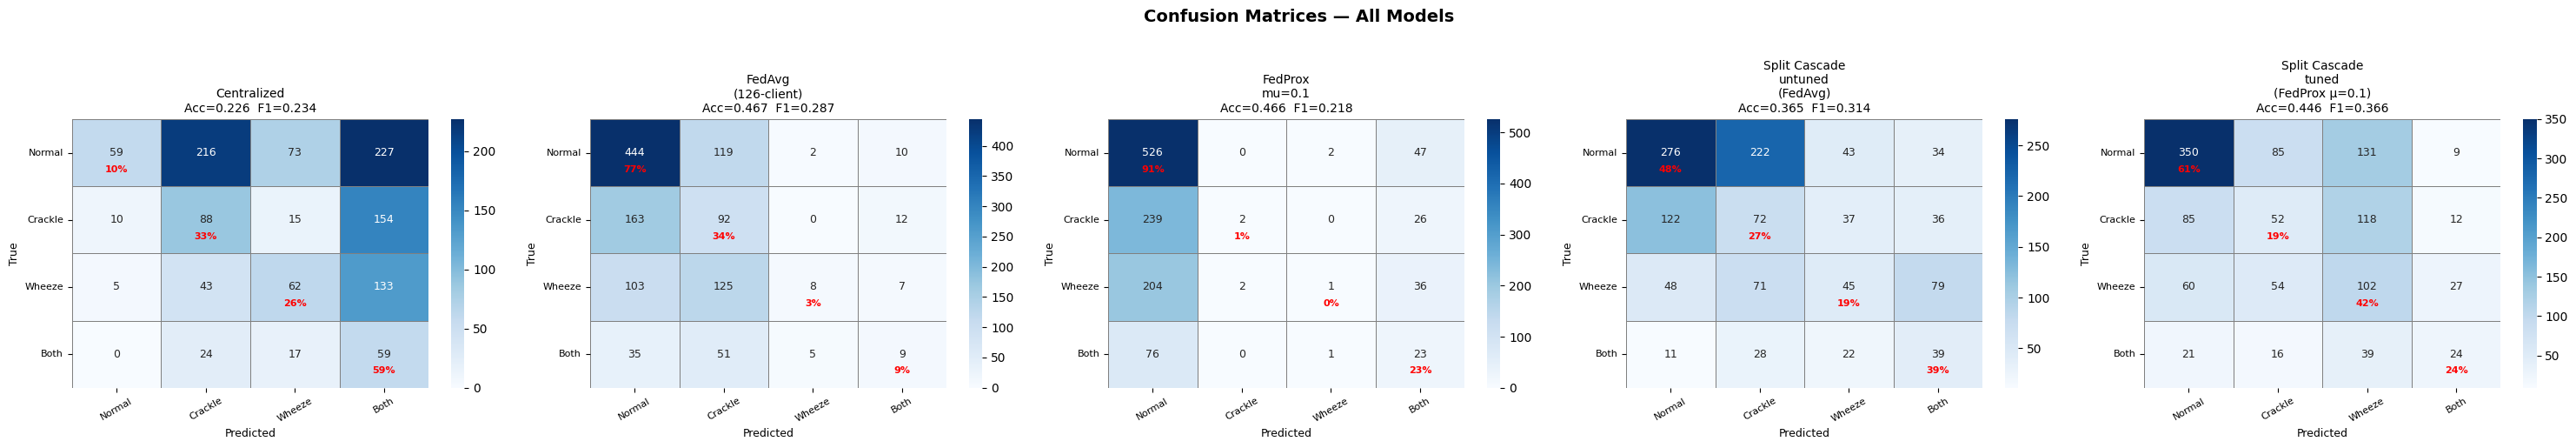

✓ Saved confusion_matrices_all.png


In [27]:
# ── Confusion matrices — all models ──────────────────────────────────────────
_, _, preds_c         = evaluate(central_model,     X_test_g, y_test_g)
_, _, preds_avg       = evaluate(global_model_avg,  X_test_g, y_test_g)
_, _, preds_prox_best = evaluate(global_model_prox, X_test_g, y_test_g)

combos = [
    (preds_c,            'Centralized'),
    (preds_avg,          'FedAvg\n(126-client)'),
    (preds_prox_best,    'FedProx\nmu=' + str(best_mu)),
    (preds_casc_untuned, 'Split Cascade\nuntuned\n(' + best_untuned_label + ')'),
    (preds_casc_tuned,   'Split Cascade\ntuned\n('   + best_tuned_label   + ')'),
]

n_plots = len(combos)
fig, axes = plt.subplots(1, n_plots, figsize=(6 * n_plots, 5))

for ax, (preds, title) in zip(axes, combos):
    cm = confusion_matrix(y_test_g, preds, labels=[0, 1, 2, 3])
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
        linewidths=0.5, linecolor='gray',
        annot_kws={'size': 9}
    )
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_pct   = np.divide(cm, row_sums, where=row_sums != 0) * 100
    for i in range(len(LABEL_NAMES)):
        ax.text(i + 0.5, i + 0.75,
                f'{cm_pct[i, i]:.0f}%',
                ha='center', va='center',
                fontsize=8, color='red', fontweight='bold')
    acc = (preds == y_test_g).mean()
    f1  = f1_score(y_test_g, preds, average='macro', zero_division=0)
    ax.set_title(title + '\nAcc=' + f'{acc:.3f}' + '  F1=' + f'{f1:.3f}', fontsize=10)
    ax.set_xlabel('Predicted', fontsize=9)
    ax.set_ylabel('True', fontsize=9)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.tick_params(axis='y', rotation=0,  labelsize=8)

plt.suptitle('Confusion Matrices — All Models',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'confusion_matrices_all.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ Saved confusion_matrices_all.png')

  OVERALL PERFORMANCE METRICS
                               Accuracy  Macro-F1  Micro-F1  Weighted-F1  Macro-Prec  Macro-Recall  F1-Normal  F1-Crackle  F1-Wheeze  F1-Both  ICBHI-Se  ICBHI-Sp  ICBHI-Score
Model                                                                                                                                                                         
Centralized                      0.2262    0.2339    0.2262       0.2272      0.3772        0.3193     0.1818      0.2759     0.3024   0.1753    0.9754    0.1026       0.5390
FedAvg (126-client)              0.4667    0.2866    0.4667       0.4135      0.4010        0.3099     0.6727      0.2813     0.0620   0.1304    0.5066    0.7722       0.6394
FedProx mu=0.1                   0.4658    0.2176    0.4658       0.3368      0.3569        0.2891     0.6494      0.0148     0.0081   0.1983    0.1492    0.9148       0.5320
Cascade untuned (FedAvg)         0.3646    0.3137    0.3646       0.3789      0.3252        0.3

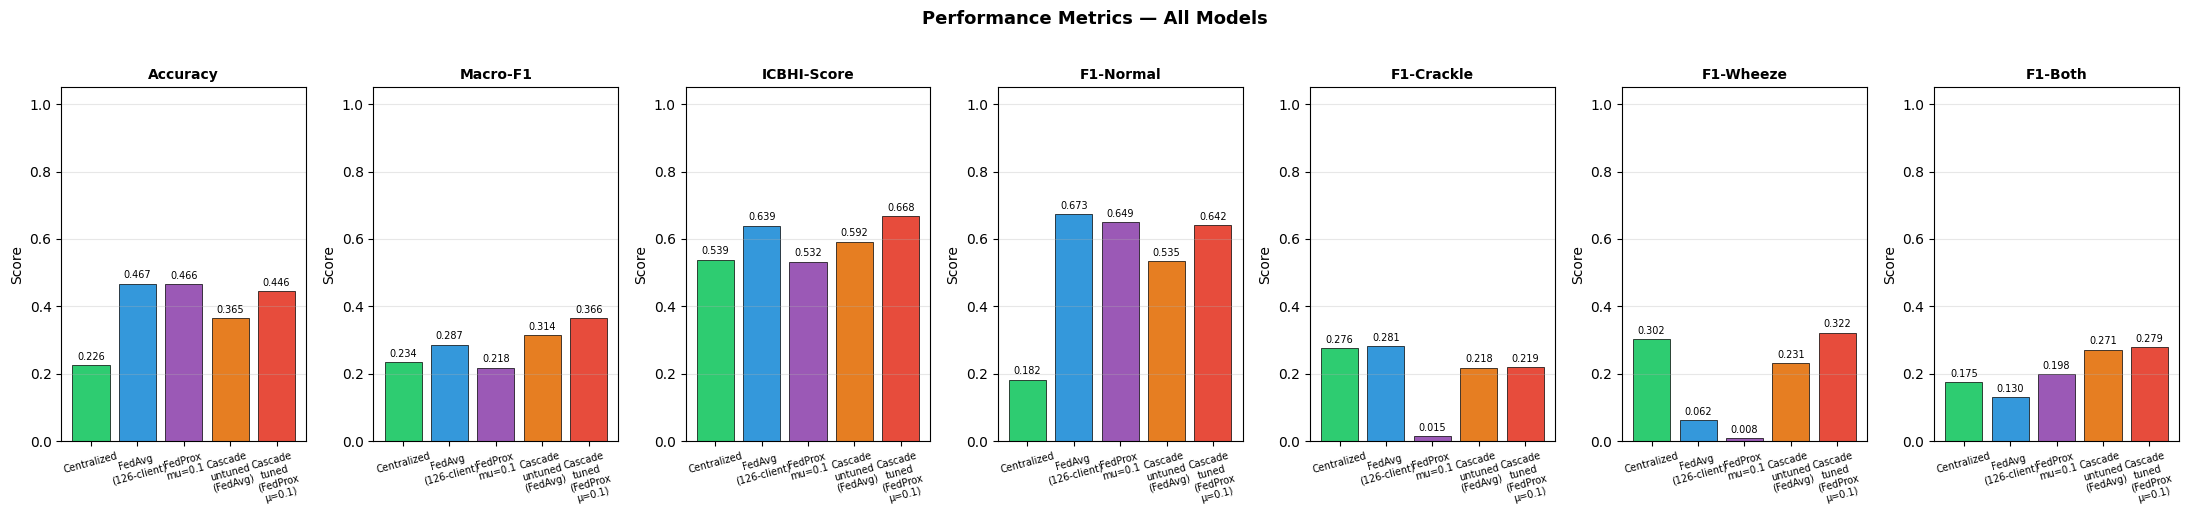

✓ Saved performance_metrics_all.png
✓ Saved performance_metrics_all.csv


In [30]:
# ── Overall Performance Metrics — All Models ──────────────────────────────────
from sklearn.metrics import precision_score, recall_score

_, _, preds_c         = evaluate(central_model,     X_test_g, y_test_g)
_, _, preds_avg       = evaluate(global_model_avg,  X_test_g, y_test_g)
_, _, preds_prox_best = evaluate(global_model_prox, X_test_g, y_test_g)

label_un = 'Cascade untuned (' + best_untuned_label + ')'
label_tu = 'Cascade tuned ('   + best_tuned_label   + ')'
label_pr = 'FedProx mu='       + str(best_mu)

models = {
    'Centralized'        : preds_c,
    'FedAvg (126-client)': preds_avg,
    label_pr             : preds_prox_best,
    label_un             : preds_casc_untuned,
    label_tu             : preds_casc_tuned,
}

rows = []
for model_name, preds in models.items():
    acc      = (preds == y_test_g).mean()
    macro_f1 = f1_score(y_test_g, preds, average='macro',    zero_division=0)
    micro_f1 = f1_score(y_test_g, preds, average='micro',    zero_division=0)
    w_f1     = f1_score(y_test_g, preds, average='weighted', zero_division=0)
    macro_p  = precision_score(y_test_g, preds, average='macro', zero_division=0)
    macro_r  = recall_score(   y_test_g, preds, average='macro', zero_division=0)

    per_class = f1_score(y_test_g, preds, average=None,
                         labels=[0, 1, 2, 3], zero_division=0)

    abn_mask = y_test_g != 0
    nor_mask = y_test_g == 0
    se    = (preds[abn_mask] != 0).sum() / abn_mask.sum() if abn_mask.sum() > 0 else 0
    sp    = (preds[nor_mask] == 0).sum() / nor_mask.sum() if nor_mask.sum() > 0 else 0
    icbhi = (se + sp) / 2

    rows.append({
        'Model'        : model_name,
        'Accuracy'     : round(float(acc),           4),
        'Macro-F1'     : round(float(macro_f1),      4),
        'Micro-F1'     : round(float(micro_f1),      4),
        'Weighted-F1'  : round(float(w_f1),          4),
        'Macro-Prec'   : round(float(macro_p),       4),
        'Macro-Recall' : round(float(macro_r),       4),
        'F1-Normal'    : round(float(per_class[0]),  4),
        'F1-Crackle'   : round(float(per_class[1]),  4),
        'F1-Wheeze'    : round(float(per_class[2]),  4),
        'F1-Both'      : round(float(per_class[3]),  4),
        'ICBHI-Se'     : round(float(se),            4),
        'ICBHI-Sp'     : round(float(sp),            4),
        'ICBHI-Score'  : round(float(icbhi),         4),
    })

df_perf = pd.DataFrame(rows).set_index('Model')

print('=' * 100)
print('  OVERALL PERFORMANCE METRICS')
print('=' * 100)
print(df_perf.to_string())
print('=' * 100)

metrics_to_plot = ['Accuracy', 'Macro-F1', 'ICBHI-Score',
                   'F1-Normal', 'F1-Crackle', 'F1-Wheeze', 'F1-Both']

fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(22, 5))
colors = ['#2ecc71', '#3498db', '#9b59b6', '#e67e22', '#e74c3c', '#1abc9c']

for ax, metric in zip(axes, metrics_to_plot):
    vals   = df_perf[metric].values
    labels = [m.replace(' ', '\n') for m in df_perf.index]
    bars   = ax.bar(labels, vals,
                    color=colors[:len(vals)],
                    edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=7)
    ax.set_title(metric, fontsize=10, fontweight='bold')
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Score')
    ax.tick_params(axis='x', labelsize=7, rotation=15)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Performance Metrics — All Models',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'performance_metrics_all.png', dpi=150, bbox_inches='tight')
plt.show()

df_perf.to_csv(RESULTS_DIR / 'performance_metrics_all.csv')
print('✓ Saved performance_metrics_all.png')
print('✓ Saved performance_metrics_all.csv')

## Step 13 — 10-Client Grouping Ablation


In [31]:
N_GROUPS = 10
pids     = sorted(client_data.keys())
groups   = np.array_split(pids, N_GROUPS)

client_data_10 = {}
for g_idx, group in enumerate(groups):
    if len(group) == 0:
        continue
    client_data_10[f'group_{g_idx}'] = {
        'X_train': np.concatenate([client_data[p]['X_train'] for p in group]),
        'y_train': np.concatenate([client_data[p]['y_train'] for p in group]),
        'X_val':   np.concatenate([client_data[p]['X_val']   for p in group]),
        'y_val':   np.concatenate([client_data[p]['y_val']   for p in group]),
    }

print(f'10-client grouping: {len(client_data_10)} super-clients')
print('Running FedAvg on 10-client grouping ...')
global_model_10, history_10 = run_fedavg(
    client_data_10, NUM_ROUNDS, LOCAL_EPOCHS, LR, BATCH_SIZE, class_weights
)
acc_10, f1_10, preds_10 = evaluate(global_model_10, X_test_g, y_test_g)
print_report(y_test_g, preds_10, 'FedAvg 10-client')
print(f'\n✅ 10-client FedAvg — Acc: {acc_10:.4f}  Macro-F1: {f1_10:.4f}')


10-client grouping: 10 super-clients
Running FedAvg on 10-client grouping ...
  Round  1/25 — Acc: 0.3949  Macro-F1: 0.3090
  Round  2/25 — Acc: 0.4219  Macro-F1: 0.2499
  Round  3/25 — Acc: 0.4371  Macro-F1: 0.2216
  Round  4/25 — Acc: 0.4844  Macro-F1: 0.1813
  Round  5/25 — Acc: 0.4827  Macro-F1: 0.1666
  Round  6/25 — Acc: 0.4835  Macro-F1: 0.1668
  Round  7/25 — Acc: 0.4827  Macro-F1: 0.1647
  Round  8/25 — Acc: 0.4827  Macro-F1: 0.1647
  Round  9/25 — Acc: 0.4810  Macro-F1: 0.1738
  Round 10/25 — Acc: 0.4827  Macro-F1: 0.1666
  Round 11/25 — Acc: 0.4802  Macro-F1: 0.1679
  Round 12/25 — Acc: 0.4802  Macro-F1: 0.1662
  Round 13/25 — Acc: 0.4776  Macro-F1: 0.1692
  Round 14/25 — Acc: 0.4768  Macro-F1: 0.1654
  Round 15/25 — Acc: 0.4819  Macro-F1: 0.1664
  Round 16/25 — Acc: 0.4819  Macro-F1: 0.1665
  Round 17/25 — Acc: 0.4751  Macro-F1: 0.1667
  Round 18/25 — Acc: 0.4692  Macro-F1: 0.1689
  Round 19/25 — Acc: 0.4700  Macro-F1: 0.1692
  Round 20/25 — Acc: 0.4675  Macro-F1: 0.1668
  

In [32]:
# ── 10-client tuned split cascade ────────────────────────────────────────────
print('Running tuned split cascade on 10-client grouping ...')
s1_w_10, s2_w_10, _, hist_casc_10 = train_split_cascade(
    client_data_10, X_test_g, y_test_g,
    mu=0.0, threshold=BEST_THRESHOLD,
    cap_ratio=BEST_CAP_RATIO, gamma=BEST_GAMMA, lr=BEST_LR, verbose=True,
)
preds_casc_10, acc_casc_10, f1_casc_10 = run_split_cascade(
    s1_w_10, s2_w_10, X_test_g, y_test_g, threshold=BEST_THRESHOLD
)
print(f'✅ Tuned split cascade (10-client) — Acc: {acc_casc_10:.4f}  Macro-F1: {f1_casc_10:.4f}')
print_report(y_test_g, preds_casc_10, 'Tuned Split Cascade (10-client)')

s1_10 = RespNet(input_dim=STFT_DIM, num_classes=2)
set_weights(s1_10, s1_w_10)
torch.save(s1_10.state_dict(), RESULTS_DIR / 'split_cascade_s1_10client.pt')
s2_10 = RespNet(input_dim=FULL_DIM, num_classes=3)
set_weights(s2_10, s2_w_10)
torch.save(s2_10.state_dict(), RESULTS_DIR / 'split_cascade_s2_10client.pt')
print('✓ 10-client split cascade models saved')


Running tuned split cascade on 10-client grouping ...
  Round   5/25 — Acc: 0.5325  Macro-F1: 0.2914  S2 clients: 10
  Round  10/25 — Acc: 0.5232  Macro-F1: 0.3069  S2 clients: 10
  Round  15/25 — Acc: 0.5046  Macro-F1: 0.3241  S2 clients: 10
  Round  20/25 — Acc: 0.5013  Macro-F1: 0.3140  S2 clients: 10
  Round  25/25 — Acc: 0.4473  Macro-F1: 0.2771  S2 clients: 10
✅ Tuned split cascade (10-client) — Acc: 0.5038  Macro-F1: 0.3293

── Tuned Split Cascade (10-client) ──
              precision    recall  f1-score   support

      Normal       0.58      0.78      0.67       575
     Crackle       0.28      0.22      0.25       267
      Wheeze       0.43      0.38      0.41       243
        Both       0.00      0.00      0.00       100

    accuracy                           0.50      1185
   macro avg       0.32      0.34      0.33      1185
weighted avg       0.44      0.50      0.46      1185

✓ 10-client split cascade models saved


## Step 14 — Patient-Level Fairness Analysis


In [33]:
fairness_rows = []
for pid in test_patients:
    mask = patients_arr == pid
    Xp   = scaler.transform(X_all[mask])
    yp   = y_all[mask]
    if len(Xp) == 0:
        continue
    acc_p, f1_p, _ = evaluate(global_model_avg, Xp, yp)
    fairness_rows.append({
        'patient': pid, 'n_cycles': len(yp),
        'accuracy': round(float(acc_p), 4),
        'macro_f1': round(float(f1_p), 4),
        'classes_present': sorted(np.unique(yp).tolist())
    })

df_fair = pd.DataFrame(fairness_rows).sort_values('macro_f1')
print('Patient-level fairness (FedAvg global model):')
print(df_fair.to_string(index=False))

low_f1 = df_fair[df_fair['macro_f1'] < 0.2]
if len(low_f1):
    print(f'\n⚠  {len(low_f1)} patients with Macro-F1 < 0.2')
else:
    print('\n✓ No patients with Macro-F1 < 0.2')

df_fair.to_csv(RESULTS_DIR / 'patient_fairness.csv', index=False)
print('✓ Saved patient_fairness.csv')


Patient-level fairness (FedAvg global model):
patient  n_cycles  accuracy  macro_f1 classes_present
    180        30    0.0000    0.0000       [1, 2, 3]
    192        46    0.0870    0.1339    [0, 1, 2, 3]
    122        52    0.2308    0.1509          [0, 2]
    199        18    0.3333    0.1739          [0, 1]
    203       185    0.4108    0.1826    [0, 1, 2, 3]
    198        98    0.2653    0.1966       [0, 1, 2]
    160       101    0.2673    0.2027    [0, 1, 2, 3]
    221        63    0.1905    0.2152       [0, 2, 3]
    168         7    0.2857    0.2222             [0]
    204        63    0.8571    0.2308          [0, 2]
    103         6    0.3333    0.2500          [0, 2]
    133       156    0.6218    0.2994    [0, 1, 2, 3]
    177        79    0.6076    0.3116    [0, 1, 2, 3]
    175        23    0.4348    0.3121       [0, 2, 3]
    117        12    0.5833    0.3684          [0, 2]
    173        13    0.6154    0.3810          [0, 1]
    167        28    0.7143    0.416

## Step 15 — Results & Plots


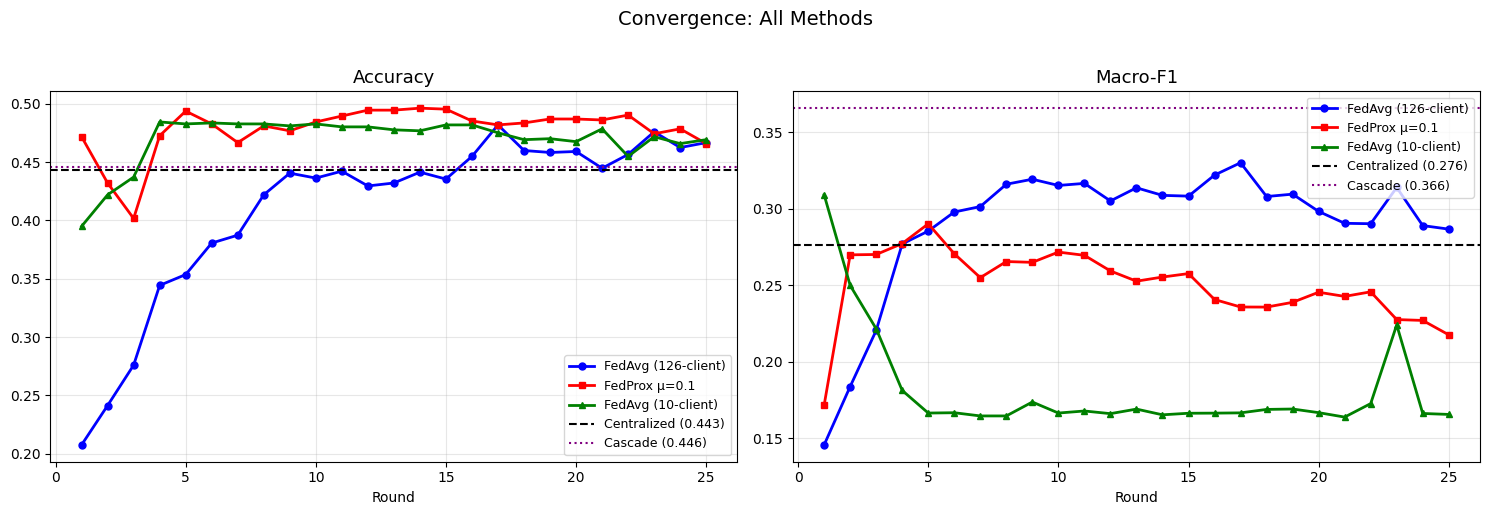

✓ Saved convergence_all.png


In [34]:
# ── Convergence curves ────────────────────────────────────────────────────────
rounds = [h['round'] for h in history_avg]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
styles = [
    (history_avg,  'FedAvg (126-client)', 'b-o'),
    (history_prox, f'FedProx μ={best_mu}', 'r-s'),
    (history_10,   'FedAvg (10-client)',  'g-^'),
]
for ax, metric, ylabel in zip(axes, ['acc', 'f1'], ['Accuracy', 'Macro-F1']):
    for hist, label, style in styles:
        ax.plot(rounds, [h[metric] for h in hist], style, label=label,
                linewidth=2, markersize=5)
    baseline = acc_c if metric == 'acc' else f1_c
    ax.axhline(baseline, color='k', linestyle='--', linewidth=1.5,
               label=f'Centralized ({baseline:.3f})')
    cascade_val = cascade_acc if metric == 'acc' else cascade_f1
    ax.axhline(cascade_val, color='purple', linestyle=':', linewidth=1.5,
               label=f'Cascade ({cascade_val:.3f})')
    ax.set_title(ylabel, fontsize=13)
    ax.set_xlabel('Round')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Convergence: All Methods', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'convergence_all.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ Saved convergence_all.png')


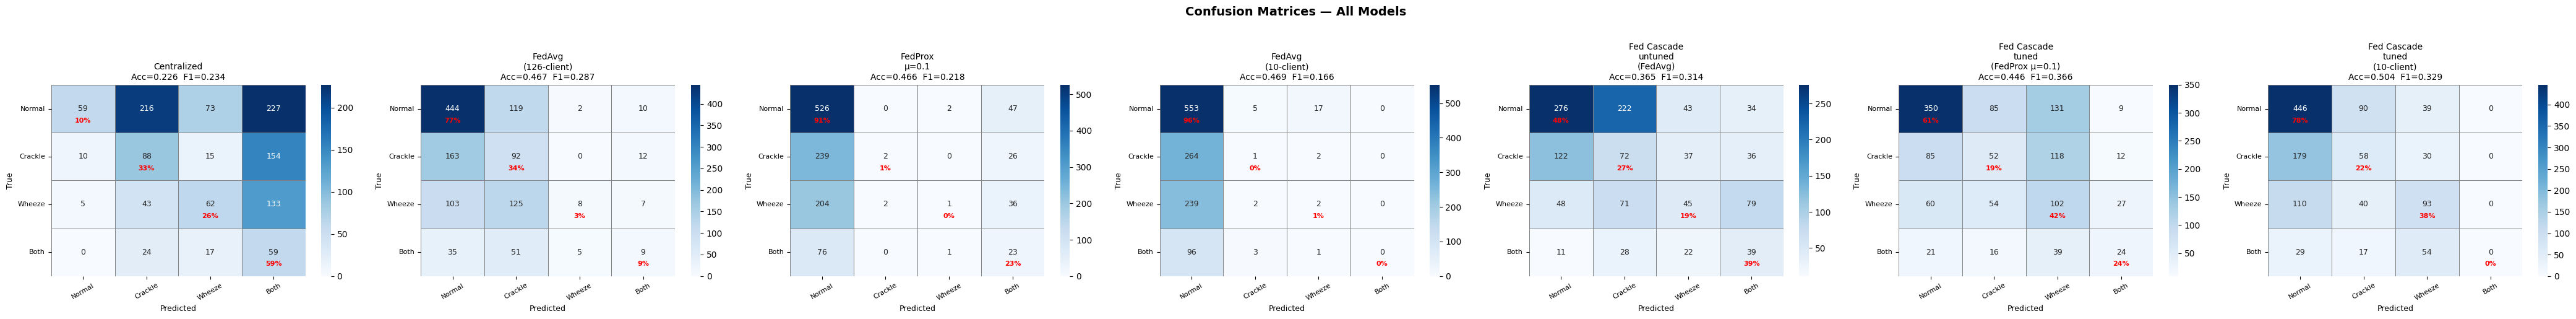

✓ Saved confusion_matrices_all.png


In [35]:
# ── Confusion matrices — all models ──────────────────────────────────────────
_, _, preds_c         = evaluate(central_model,    X_test_g, y_test_g)
_, _, preds_avg       = evaluate(global_model_avg, X_test_g, y_test_g)
_, _, preds_prox_best = evaluate(global_model_prox,X_test_g, y_test_g)

combos = [
    (preds_c,            'Centralized'),
    (preds_avg,          'FedAvg\n(126-client)'),
    (preds_prox_best,    f'FedProx\nμ={best_mu}'),
    (preds_10,           'FedAvg\n(10-client)'),
    (preds_casc_untuned, f'Fed Cascade\nuntuned\n({best_untuned_label})'),
    (preds_casc_tuned,   f'Fed Cascade\ntuned\n({best_tuned_label})'),
    (preds_casc_10,      'Fed Cascade\ntuned\n(10-client)'),
]

n_plots = len(combos)
fig, axes = plt.subplots(1, n_plots, figsize=(6 * n_plots, 5))

for ax, (preds, title) in zip(axes, combos):
    cm = confusion_matrix(y_test_g, preds, labels=[0, 1, 2, 3])
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
        linewidths=0.5, linecolor='gray',
        annot_kws={'size': 9}
    )
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_pct   = np.divide(cm, row_sums, where=row_sums != 0) * 100
    for i in range(len(LABEL_NAMES)):
        ax.text(i + 0.5, i + 0.75,
                f'{cm_pct[i, i]:.0f}%',
                ha='center', va='center',
                fontsize=8, color='red', fontweight='bold')
    acc = (preds == y_test_g).mean()
    f1  = f1_score(y_test_g, preds, average='macro', zero_division=0)
    ax.set_title(f'{title}\nAcc={acc:.3f}  F1={f1:.3f}', fontsize=10)
    ax.set_xlabel('Predicted', fontsize=9)
    ax.set_ylabel('True', fontsize=9)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.tick_params(axis='y', rotation=0,  labelsize=8)

plt.suptitle('Confusion Matrices — All Models',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'confusion_matrices_all.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ Saved confusion_matrices_all.png')

In [36]:
# ── Final summary ─────────────────────────────────────────────────────────────
acc_avg_f, f1_avg_f, _ = evaluate(global_model_avg, X_test_g, y_test_g)
acc_10_f,  f1_10_f,  _ = evaluate(global_model_10,  X_test_g, y_test_g)

summary = {
    'dataset': 'ICBHI 2017', 'num_clients': NUM_CLIENTS,
    'num_rounds': NUM_ROUNDS, 'local_epochs': LOCAL_EPOCHS,
    'best_fedprox_mu': best_mu,
    'features': 'STFT+LogMel 256-dim + bandpass 100-1900Hz',
    'Centralized':  {'accuracy': round(acc_c,     4), 'macro_f1': round(f1_c,     4)},
    'FedAvg_126':   {'accuracy': round(acc_avg_f, 4), 'macro_f1': round(f1_avg_f, 4)},
    'FedAvg_10':    {'accuracy': round(acc_10_f,  4), 'macro_f1': round(f1_10_f,  4)},
    'Cascade':      {'accuracy': round(cascade_acc, 4), 'macro_f1': round(cascade_f1, 4)},
    'FedProx': {
        str(mu): {'accuracy': round(prox_results[mu]['acc'], 4),
                  'macro_f1': round(prox_results[mu]['f1'],  4)}
        for mu in MU_SWEEP
    },
}
with open(RESULTS_DIR / 'results_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print('=' * 62)
print('               FINAL RESULTS SUMMARY')
print('=' * 62)
print(f'  Features       : STFT + Log-Mel  ({FEATURE_DIM} dims)')
print(f'  Bandpass       : {LOWCUT}–{HIGHCUT} Hz')
print(f'  Clients        : {NUM_CLIENTS}  (+ 10-client grouping)')
print(f'  Rounds         : {NUM_ROUNDS}  ×  {LOCAL_EPOCHS} local epochs')
print(f'  Best FedProx μ : {best_mu}')
print('-' * 62)
print(f'  Centralized    → Acc: {acc_c:.4f}   Macro-F1: {f1_c:.4f}')
print(f'  FedAvg (126)   → Acc: {acc_avg_f:.4f}   Macro-F1: {f1_avg_f:.4f}')
print(f'  FedAvg (10)    → Acc: {acc_10_f:.4f}   Macro-F1: {f1_10_f:.4f}')
for mu in MU_SWEEP:
    r = prox_results[mu]
    mark = ' ← best' if mu == best_mu else ''
    print(f'  FedProx μ={mu:<5} → Acc: {r["acc"]:.4f}   Macro-F1: {r["f1"]:.4f}{mark}')
print(f'  Two-Stage Cas. → Acc: {cascade_acc:.4f}   Macro-F1: {cascade_f1:.4f}')
print('=' * 62)
print(f'\n✅ All results saved to {RESULTS_DIR.resolve()}')


               FINAL RESULTS SUMMARY
  Features       : STFT + Log-Mel  (256 dims)
  Bandpass       : 100–1900 Hz
  Clients        : 100  (+ 10-client grouping)
  Rounds         : 25  ×  3 local epochs
  Best FedProx μ : 0.1
--------------------------------------------------------------
  Centralized    → Acc: 0.4430   Macro-F1: 0.2761
  FedAvg (126)   → Acc: 0.4667   Macro-F1: 0.2866
  FedAvg (10)    → Acc: 0.4692   Macro-F1: 0.1657
  FedProx μ=0.1   → Acc: 0.4658   Macro-F1: 0.2176 ← best
  FedProx μ=0.5   → Acc: 0.1055   Macro-F1: 0.0789
  FedProx μ=1.0   → Acc: 0.1502   Macro-F1: 0.1237
  Two-Stage Cas. → Acc: 0.4456   Macro-F1: 0.3656

✅ All results saved to /home/ramima/icbhi_fl/results


In [38]:
for min_c in [5, 10, 20, 30]:
    valid = [p for p in unique_patients
             if (patients_arr == p).sum() >= min_c]
    print(f'MIN_CYCLES={min_c}: {len(valid)} clients qualify')
    

MIN_CYCLES=5: 124 clients qualify
MIN_CYCLES=10: 100 clients qualify
MIN_CYCLES=20: 71 clients qualify
MIN_CYCLES=30: 61 clients qualify


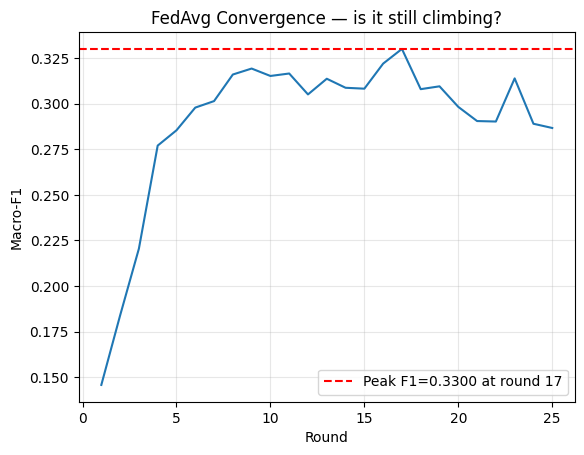

In [40]:
# Plot F1 at each round to check convergence
rounds = [h['round'] for h in history_avg]
f1s    = [h['f1']    for h in history_avg]
plt.plot(rounds, f1s)
plt.axhline(max(f1s), color='r', linestyle='--',
            label=f'Peak F1={max(f1s):.4f} at round {f1s.index(max(f1s))+1}')
plt.xlabel('Round')
plt.ylabel('Macro-F1')
plt.title('FedAvg Convergence — is it still climbing?')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


         ABLATION STUDY — BEFORE vs AFTER COMPARISON

PARAMETERS CHANGED BY ABLATION:
  Stage 1 Threshold : 0.50  ->  0.5
  cap_ratio         : 2.50  ->  2.0
  Focal Loss gamma  : 2.00  ->  3.0
  Learning Rate     : 1e-03  ->  3e-03
  Stage 1 features  : 128-dim STFT only
  Stage 2 features  : 256-dim STFT + LogMel

OVERALL METRICS:
        Metric      Untuned        Tuned       Change
  --------------------------------------------------
      Accuracy       0.3646       0.4456   +    0.0810
      Macro-F1       0.3137       0.3656   +    0.0519

PER-CLASS F1 SCORE:
         Class      Untuned        Tuned       Change
  --------------------------------------------------
        Normal       0.5349       0.6416   +    0.1067 UP
       Crackle       0.2182       0.2194   +    0.0012 UP
        Wheeze       0.2308       0.3223   +    0.0915 UP
          Both       0.2708       0.2791   +    0.0082 UP

STAGE 1 ROUTING COMPARISON:
                              Untuned (thr=0.5)      Tuned 

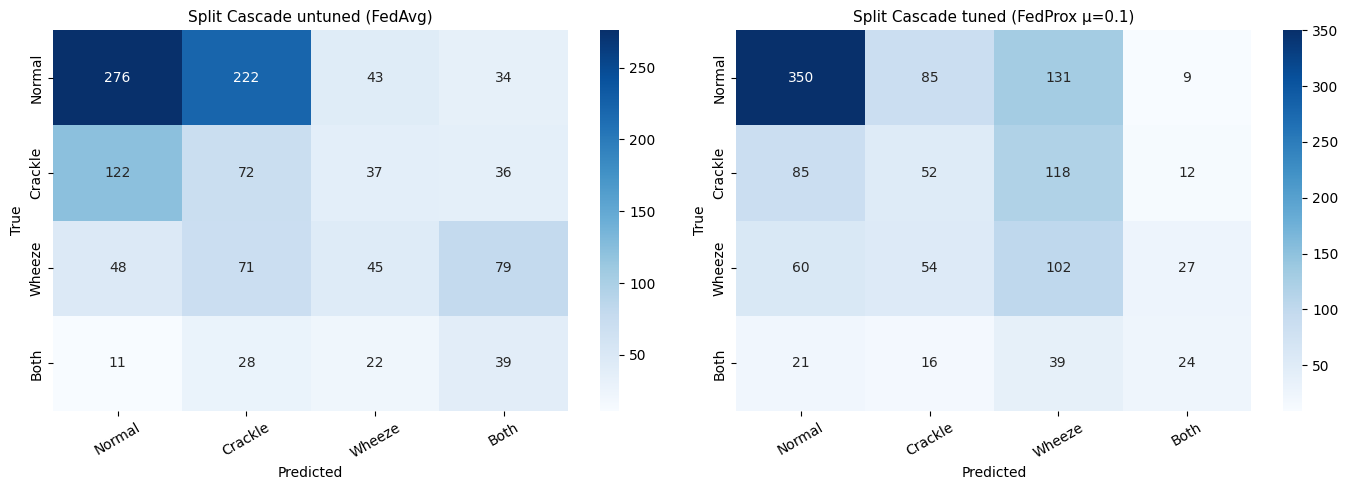

Saved ablation_comparison.png
Ablation summary saved to results/ablation_summary.json


In [42]:
# ── Ablation Study — Before vs After Comparison ───────────────────────────────
print('=' * 65)
print('         ABLATION STUDY — BEFORE vs AFTER COMPARISON')
print('=' * 65)

# ── Parameters ────────────────────────────────────────────────────────────────
print('\nPARAMETERS CHANGED BY ABLATION:')
print(f'  Stage 1 Threshold : 0.50  ->  {BEST_THRESHOLD}')
print(f'  cap_ratio         : 2.50  ->  {BEST_CAP_RATIO}')
print(f'  Focal Loss gamma  : 2.00  ->  {BEST_GAMMA}')
print(f'  Learning Rate     : {LR:.0e}  ->  {BEST_LR:.0e}')
print(f'  Stage 1 features  : 128-dim STFT only')
print(f'  Stage 2 features  : 256-dim STFT + LogMel')

# ── Overall metrics ───────────────────────────────────────────────────────────
print('\nOVERALL METRICS:')
print(f'  {"Metric":>12}   {"Untuned":>10}   {"Tuned":>10}   {"Change":>10}')
print(f'  {"-"*50}')

orig_acc = acc_casc_untuned
orig_f1  = f1_casc_untuned
tuned_acc = acc_casc_tuned
tuned_f1  = f1_casc_tuned

sign_acc = '+' if tuned_acc - orig_acc >= 0 else ''
sign_f1  = '+' if tuned_f1  - orig_f1  >= 0 else ''
print(f'  {"Accuracy":>12}   {orig_acc:>10.4f}   {tuned_acc:>10.4f}   {sign_acc}{tuned_acc - orig_acc:>10.4f}')
print(f'  {"Macro-F1":>12}   {orig_f1:>10.4f}   {tuned_f1:>10.4f}   {sign_f1}{tuned_f1  - orig_f1:>10.4f}')

# ── Per-class F1 ──────────────────────────────────────────────────────────────
print('\nPER-CLASS F1 SCORE:')
print(f'  {"Class":>12}   {"Untuned":>10}   {"Tuned":>10}   {"Change":>10}')
print(f'  {"-"*50}')

for i, name in enumerate(LABEL_NAMES):
    f1_un  = f1_score(y_test_g == i, preds_casc_untuned == i, zero_division=0)
    f1_tu  = f1_score(y_test_g == i, preds_casc_tuned   == i, zero_division=0)
    change = f1_tu - f1_un
    flag   = ' UP' if change > 0 else (' DOWN' if change < 0 else '')
    sign   = '+' if change >= 0 else ''
    print(f'  {name:>12}   {f1_un:>10.4f}   {f1_tu:>10.4f}   {sign}{change:>10.4f}{flag}')

# ── Stage 1 routing comparison ────────────────────────────────────────────────
print('\nSTAGE 1 ROUTING COMPARISON:')

# Recompute Stage 1 probs using the saved untuned and tuned S1 models
s1_un_model = RespNet(input_dim=STFT_DIM, num_classes=2)
set_weights(s1_un_model, s1_w_def_avg)
s1_un_model.eval()

s1_tu_model = RespNet(input_dim=STFT_DIM, num_classes=2)
set_weights(s1_tu_model, s1_w_tuned_avg)
s1_tu_model.eval()

X_test_stft = X_test_g[:, :STFT_DIM]

with torch.no_grad():
    prob_un = torch.softmax(
        s1_un_model(torch.tensor(X_test_stft, dtype=torch.float32)), dim=1
    )[:, 1].numpy()
    prob_tu = torch.softmax(
        s1_tu_model(torch.tensor(X_test_stft, dtype=torch.float32)), dim=1
    )[:, 1].numpy()

route_un = (prob_un >= S1_THRESHOLD).astype(int)
route_tu = (prob_tu >= BEST_THRESHOLD).astype(int)
true_abn = y_test_g != 0

print(f'  {"":>22}   {"Untuned (thr="+str(S1_THRESHOLD)+")":>20}   {"Tuned (thr="+str(BEST_THRESHOLD)+")":>18}')
print(f'  {"-"*65}')
print(f'  {"Sent to Normal":>22}   {(route_un==0).sum():>20}   {(route_tu==0).sum():>18}')
print(f'  {"Sent to Stage 2":>22}   {(route_un==1).sum():>20}   {(route_tu==1).sum():>18}')

routed_un = ((route_un == 1) & true_abn).sum()
routed_tu = ((route_tu == 1) & true_abn).sum()
total_abn = true_abn.sum()

print(f'  {"True abnormals":>22}   {total_abn:>20}   {total_abn:>18}')
print(f'  {"Correctly routed":>22}   {routed_un:>20}   {routed_tu:>18}')
print(f'  {"Routing recall":>22}   {routed_un/total_abn:>20.4f}   {routed_tu/total_abn:>18.4f}')

# ── Confusion matrices ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, preds, title in zip(
    axes,
    [preds_casc_untuned, preds_casc_tuned],
    ['Split Cascade untuned (' + best_untuned_label + ')',
     'Split Cascade tuned ('   + best_tuned_label   + ')']
):
    cm = confusion_matrix(y_test_g, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'ablation_comparison.png', dpi=150)
plt.show()
print('Saved ablation_comparison.png')

# ── Save summary JSON ─────────────────────────────────────────────────────────
ablation_summary = {
    'stage1_features'   : 'STFT-only 128-dim',
    'stage2_features'   : 'STFT+LogMel 256-dim',
    'untuned_cascade': {
        'threshold': S1_THRESHOLD,
        'cap_ratio': CAP_RATIO_FED,
        'gamma'    : GAMMA_FED,
        'lr'       : LR_FED,
        'accuracy' : round(float(orig_acc),  4),
        'macro_f1' : round(float(orig_f1),   4),
    },
    'tuned_cascade': {
        'threshold': BEST_THRESHOLD,
        'cap_ratio': BEST_CAP_RATIO,
        'gamma'    : BEST_GAMMA,
        'lr'       : BEST_LR,
        'accuracy' : round(float(tuned_acc), 4),
        'macro_f1' : round(float(tuned_f1),  4),
    },
    'improvement': {
        'accuracy' : round(float(tuned_acc - orig_acc), 4),
        'macro_f1' : round(float(tuned_f1  - orig_f1),  4),
    }
}

with open(RESULTS_DIR / 'ablation_summary.json', 'w') as f:
    json.dump(ablation_summary, f, indent=2)

print('Ablation summary saved to results/ablation_summary.json')
print('=' * 65)

In [44]:
# ── ICBHI Score, Sensitivity, Specificity ─────────────────────────────────────
from sklearn.metrics import confusion_matrix
import numpy as np

def icbhi_metrics(y_true, y_pred, label_names=LABEL_NAMES):
    cm        = confusion_matrix(y_true, y_pred, labels=list(range(len(label_names))))
    n_classes = len(label_names)
    rows      = []

    for i in range(n_classes):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = cm.sum() - TP - FN - FP

        sensitivity = TP / (TP + FN) if (TP + FN) > 0 else 0.0
        specificity = TN / (TN + FP) if (TN + FP) > 0 else 0.0
        icbhi_score = (sensitivity + specificity) / 2

        rows.append({
            'Class'      : label_names[i],
            'TP'         : int(TP),
            'FP'         : int(FP),
            'TN'         : int(TN),
            'FN'         : int(FN),
            'Sensitivity': round(sensitivity, 4),
            'Specificity': round(specificity, 4),
            'ICBHI Score': round(icbhi_score, 4),
        })

    avg_sens  = np.mean([r['Sensitivity'] for r in rows])
    avg_spec  = np.mean([r['Specificity'] for r in rows])
    avg_icbhi = (avg_sens + avg_spec) / 2

    rows.append({
        'Class'      : 'MACRO AVG',
        'TP'         : '-', 'FP': '-', 'TN': '-', 'FN': '-',
        'Sensitivity': round(avg_sens,  4),
        'Specificity': round(avg_spec,  4),
        'ICBHI Score': round(avg_icbhi, 4),
    })

    return pd.DataFrame(rows)


# ── Evaluate all models ───────────────────────────────────────────────────────
_, _, preds_c   = evaluate(central_model,     X_test_g, y_test_g)
_, _, preds_avg = evaluate(global_model_avg,  X_test_g, y_test_g)

label_un = 'Cascade untuned (' + best_untuned_label + ')'
label_tu = 'Cascade tuned ('   + best_tuned_label   + ')'

models_to_eval = {
    'Centralized'  : preds_c,
    'FedAvg 126'   : preds_avg,
    label_un       : preds_casc_untuned,
    label_tu       : preds_casc_tuned,
}

# Add 10-client if already run
try:
    _, _, preds_10_icbhi = evaluate(global_model_10, X_test_g, y_test_g)
    models_to_eval['FedAvg 10-client'] = preds_10_icbhi
except NameError:
    pass

all_icbhi = {}

for model_name, preds in models_to_eval.items():
    print('\n' + '=' * 60)
    print('  ' + model_name)
    print('=' * 60)
    df_metrics = icbhi_metrics(y_test_g, preds)
    print(df_metrics.to_string(index=False))
    all_icbhi[model_name] = df_metrics


# ── Summary table ─────────────────────────────────────────────────────────────
print('\n' + '=' * 60)
print('  ICBHI SCORE SUMMARY (Macro Average)')
print('=' * 60)
print(f'  {"Model":30s}  {"Sensitivity":>12}  {"Specificity":>12}  {"ICBHI Score":>12}')
print(f'  {"-"*60}')
for model_name, df in all_icbhi.items():
    macro = df[df['Class'] == 'MACRO AVG'].iloc[0]
    print(f'  {model_name:30s}  {macro["Sensitivity"]:>12}  {macro["Specificity"]:>12}  {macro["ICBHI Score"]:>12}')
print('=' * 60)


# ── Save to CSV ───────────────────────────────────────────────────────────────
for model_name, df in all_icbhi.items():
    safe_name = model_name.replace(' ', '_').replace('(', '').replace(')', '').replace('=','')
    df.to_csv(RESULTS_DIR / ('icbhi_metrics_' + safe_name + '.csv'), index=False)

print('\nICBHI metrics saved to ' + str(RESULTS_DIR.resolve()))


  Centralized
    Class TP  FP  TN  FN  Sensitivity  Specificity  ICBHI Score
   Normal 59  15 595 516       0.1026       0.9754       0.5390
  Crackle 88 283 635 179       0.3296       0.6917       0.5107
   Wheeze 62 105 837 181       0.2551       0.8885       0.5718
     Both 59 514 571  41       0.5900       0.5263       0.5581
MACRO AVG  -   -   -   -       0.3193       0.7705       0.5449

  FedAvg 126
    Class  TP  FP   TN  FN  Sensitivity  Specificity  ICBHI Score
   Normal 444 301  309 131       0.7722       0.5066       0.6394
  Crackle  92 295  623 175       0.3446       0.6786       0.5116
   Wheeze   8   7  935 235       0.0329       0.9926       0.5127
     Both   9  29 1056  91       0.0900       0.9733       0.5316
MACRO AVG   -   -    -   -       0.3099       0.7878       0.5489

  Cascade untuned (FedAvg)
    Class  TP  FP  TN  FN  Sensitivity  Specificity  ICBHI Score
   Normal 276 181 429 299       0.4800       0.7033       0.5916
  Crackle  72 321 597 195       0

In [45]:
# FedProx per μ value
print(f'\n{"="*60}')
print('  FedProx — per μ value')
print(f'{"="*60}')
for mu_val in MU_SWEEP:
    preds_mu = prox_results[mu_val]['preds']
    df_mu    = icbhi_metrics(y_test_g, preds_mu)
    macro    = df_mu[df_mu['Class'] == 'MACRO AVG'].iloc[0]
    print(f'  μ={mu_val:<5}  Sensitivity={macro["Sensitivity"]}  '
          f'Specificity={macro["Specificity"]}  ICBHI={macro["ICBHI Score"]}')
    df_mu.to_csv(RESULTS_DIR / f'icbhi_metrics_FedProx_mu{mu_val}.csv', index=False)


  FedProx — per μ value
  μ=0.1    Sensitivity=0.2891  Specificity=0.7608  ICBHI=0.525
  μ=0.5    Sensitivity=0.2598  Specificity=0.7528  ICBHI=0.5063
  μ=1.0    Sensitivity=0.2842  Specificity=0.7512  ICBHI=0.5177
